# Momentum Strategy Code vvv

#### Import all modules, packages, tools to be used in the code.

In [3]:
import numpy as np
import pandas as pd
import pandas_datareader as pdr
import matplotlib.pyplot as plt
import mplfinance as mpf
import seaborn as sns
import itertools
import os
import re
import datetime 
from zipfile import ZipFile
import pandas_gbq
import janitor
import shutil
import glob
from google.cloud import bigquery
from google.oauth2 import service_account

In [4]:
# pd.set_option('display.max_columns', None)

In [5]:
pd.set_option('display.max_rows', 30)
pd.set_option('display.min_rows', 30)

* Read in ES data to ES and change the column names to make sense. 
* Drop NA's to avoid issues, convert date data type, 
* sort date appropriately, add day number, set index to date.

In [6]:
ES = pd.read_csv('ES_Granular/ES_continuous_adjusted_1hour.txt', names = ['Date', 'Open', 'High', 'Low', 'Close', 'Volume'])
ES.dropna(inplace=True)
# ES

In [7]:
# ES = pd.read_csv('HistoricalData_ES.csv') #reads in ES data to ES
# ES['Close'] = ES['Close/Last'] #copies said column
# ES.drop(columns = ['Close/Last'], inplace = True) #drops 'columns' from dataframe, inplace makes it permanent
# ES = ES[['Date', 'Open', 'Close', 'High', 'Low', 'Volume']] #orders columns
# ES.dropna(inplace=True) #drops records that we can't really use 
# ES #prints top and bottom five records of dataframe

In [8]:
ES['Date']=pd.to_datetime(ES.Date) #converts Date columns to datetime format
ES = ES.sort_values(['Date'], ascending = True) #sorts by Date column so earliest is first
# ES

In [9]:
day = np.arange(1, len(ES) + 1) #creates day column
ES['Day'] = day #adds day column to dataframe
#ES.reset_index(drop = True, inplace = True)
ES = ES.set_index('Date')

#ES

In [10]:
# #adjust the volume ma here
# vma = 5
ES['candle_average']=(ES['High']+ ES['Low']+ES['Open']+ES['Close'])/4 #creates average of our price metrics
# ES['vma']=ES['Volume'].rolling(vma).mean()#.shift() #creates volume moving average using vma as input
# #ES

In [11]:
# Creating a copy of the table for weighted ma calculations
ESw = ES.copy()
ESe = ES.copy()

# Simple Moving Average Iteration

In [12]:
LongMAs = list(range(1, 51))
SignalMAs = list(range(1, 51))
prix_met = 'Open'
prix_met_2 = 'Close'

### These cells iterate through lists of moving average periods and creates a column for each.

In [13]:
for ma in LongMAs :
    ES[ma] = ES[prix_met].rolling(ma).mean()
#     break

In [14]:
# ES

In [15]:
new_names_lma = []
old_names_lma = []

for ma in LongMAs :
    new_names_lma.append(str(ma)+'_lma')
    old_names_lma.append(ma)
print(new_names_lma)
print(old_names_lma)

ES.rename(columns=dict(zip(old_names_lma, new_names_lma)), inplace = True)

['1_lma', '2_lma', '3_lma', '4_lma', '5_lma', '6_lma', '7_lma', '8_lma', '9_lma', '10_lma', '11_lma', '12_lma', '13_lma', '14_lma', '15_lma', '16_lma', '17_lma', '18_lma', '19_lma', '20_lma', '21_lma', '22_lma', '23_lma', '24_lma', '25_lma', '26_lma', '27_lma', '28_lma', '29_lma', '30_lma', '31_lma', '32_lma', '33_lma', '34_lma', '35_lma', '36_lma', '37_lma', '38_lma', '39_lma', '40_lma', '41_lma', '42_lma', '43_lma', '44_lma', '45_lma', '46_lma', '47_lma', '48_lma', '49_lma', '50_lma']
[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50]


In [16]:
# ES

In [17]:
for ma in SignalMAs :
    ES[ma] = ES[prix_met].rolling(ma).mean()

new_names_sma = []
old_names_sma = []

for ma in SignalMAs :
    new_names_sma.append(str(ma)+'_sma')
    old_names_sma.append(ma)
print(new_names_sma)
print(old_names_sma)

ES.rename(columns=dict(zip(old_names_sma, new_names_sma)), inplace = True)

['1_sma', '2_sma', '3_sma', '4_sma', '5_sma', '6_sma', '7_sma', '8_sma', '9_sma', '10_sma', '11_sma', '12_sma', '13_sma', '14_sma', '15_sma', '16_sma', '17_sma', '18_sma', '19_sma', '20_sma', '21_sma', '22_sma', '23_sma', '24_sma', '25_sma', '26_sma', '27_sma', '28_sma', '29_sma', '30_sma', '31_sma', '32_sma', '33_sma', '34_sma', '35_sma', '36_sma', '37_sma', '38_sma', '39_sma', '40_sma', '41_sma', '42_sma', '43_sma', '44_sma', '45_sma', '46_sma', '47_sma', '48_sma', '49_sma', '50_sma']
[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50]


C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1312623726.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  ES[ma] = ES[prix_met].rolling(ma).mean()
C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1312623726.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  ES[ma] = ES[prix_met].rolling(ma).mean()
C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1312623726.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joi

In [18]:
# Defragging ES
ES = ES.copy()
ES

,Open,High,Low,Close,Volume,Day,candle_average,1_lma,2_lma,3_lma,...,41_sma,42_sma,43_sma,44_sma,45_sma,46_sma,47_sma,48_sma,49_sma,50_sma
Date,,,,,,,,,,,,,,,,,,,,,
2005-09-06 16:00:00,1146.25,1146.75,1146.00,1146.50,1711,1,1146.3750,1146.25,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2005-09-06 17:00:00,1146.25,1146.75,1146.25,1146.50,744,2,1146.4375,1146.25,1146.250,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2005-09-06 18:00:00,1146.50,1146.75,1146.00,1146.25,395,3,1146.3750,1146.50,1146.375,1146.333333,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2005-09-06 19:00:00,1146.00,1146.25,1146.00,1146.00,280,4,1146.0625,1146.00,1146.250,1146.250000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2005-09-06 20:00:00,1146.25,1146.50,1146.00,1146.00,370,5,1146.1875,1146.25,1146.125,1146.250000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2005-09-06 21:00:00,1146.25,1146.25,1145.75,1146.00,329,6,1146.0625,1146.25,1146.250,1146.166667,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2005-09-06 22:00:00,1145.75,1146.25,1145.75,1146.00,312,7,1145.9375,1145.75,1146.000,1146.083333,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2005-09-06 23:00:00,1146.00,1146.25,1145.50,1145.75,637,8,1145.8750,1146.00,1145.875,1146.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2005-09-07 00:00:00,1145.50,1146.00,1145.50,1146.00,148,9,1145.7500,1145.50,1145.750,1145.750000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Next we'll iterate through our lma and sma columns and generate pairwise signals.

In [19]:
list(itertools.product(new_names_lma, new_names_sma))

[('1_lma', '1_sma'),
 ('1_lma', '2_sma'),
 ('1_lma', '3_sma'),
 ('1_lma', '4_sma'),
 ('1_lma', '5_sma'),
 ('1_lma', '6_sma'),
 ('1_lma', '7_sma'),
 ('1_lma', '8_sma'),
 ('1_lma', '9_sma'),
 ('1_lma', '10_sma'),
 ('1_lma', '11_sma'),
 ('1_lma', '12_sma'),
 ('1_lma', '13_sma'),
 ('1_lma', '14_sma'),
 ('1_lma', '15_sma'),
 ('1_lma', '16_sma'),
 ('1_lma', '17_sma'),
 ('1_lma', '18_sma'),
 ('1_lma', '19_sma'),
 ('1_lma', '20_sma'),
 ('1_lma', '21_sma'),
 ('1_lma', '22_sma'),
 ('1_lma', '23_sma'),
 ('1_lma', '24_sma'),
 ('1_lma', '25_sma'),
 ('1_lma', '26_sma'),
 ('1_lma', '27_sma'),
 ('1_lma', '28_sma'),
 ('1_lma', '29_sma'),
 ('1_lma', '30_sma'),
 ('1_lma', '31_sma'),
 ('1_lma', '32_sma'),
 ('1_lma', '33_sma'),
 ('1_lma', '34_sma'),
 ('1_lma', '35_sma'),
 ('1_lma', '36_sma'),
 ('1_lma', '37_sma'),
 ('1_lma', '38_sma'),
 ('1_lma', '39_sma'),
 ('1_lma', '40_sma'),
 ('1_lma', '41_sma'),
 ('1_lma', '42_sma'),
 ('1_lma', '43_sma'),
 ('1_lma', '44_sma'),
 ('1_lma', '45_sma'),
 ('1_lma', '46_sma'

In [20]:
# This is the hog.
signal_cols = []

for lname in new_names_lma :
    for sname in new_names_sma :
#         if pd.to_numeric(re.findall(r'\d+', lname)) > pd.to_numeric(re.findall(r'\d+', sname)) :
        ES[f"{lname} {sname} signal"] = np.where(ES[sname] > ES[lname], 1, 0) #long signal
        ES[f"{lname} {sname} signal"] = np.where(ES[sname] < ES[lname], -1, ES[f"{lname} {sname} signal"]) #short signal
        ES.dropna(inplace=True) #drops records that we can't really use due to nature of sma's
        signal_cols.append(f"{lname} {sname} signal")

In [21]:
signal_cols

['1_lma 1_sma signal',
 '1_lma 2_sma signal',
 '1_lma 3_sma signal',
 '1_lma 4_sma signal',
 '1_lma 5_sma signal',
 '1_lma 6_sma signal',
 '1_lma 7_sma signal',
 '1_lma 8_sma signal',
 '1_lma 9_sma signal',
 '1_lma 10_sma signal',
 '1_lma 11_sma signal',
 '1_lma 12_sma signal',
 '1_lma 13_sma signal',
 '1_lma 14_sma signal',
 '1_lma 15_sma signal',
 '1_lma 16_sma signal',
 '1_lma 17_sma signal',
 '1_lma 18_sma signal',
 '1_lma 19_sma signal',
 '1_lma 20_sma signal',
 '1_lma 21_sma signal',
 '1_lma 22_sma signal',
 '1_lma 23_sma signal',
 '1_lma 24_sma signal',
 '1_lma 25_sma signal',
 '1_lma 26_sma signal',
 '1_lma 27_sma signal',
 '1_lma 28_sma signal',
 '1_lma 29_sma signal',
 '1_lma 30_sma signal',
 '1_lma 31_sma signal',
 '1_lma 32_sma signal',
 '1_lma 33_sma signal',
 '1_lma 34_sma signal',
 '1_lma 35_sma signal',
 '1_lma 36_sma signal',
 '1_lma 37_sma signal',
 '1_lma 38_sma signal',
 '1_lma 39_sma signal',
 '1_lma 40_sma signal',
 '1_lma 41_sma signal',
 '1_lma 42_sma signal',
 

In [22]:
ES = ES.copy()
ES

,Open,High,Low,Close,Volume,Day,candle_average,1_lma,2_lma,3_lma,...,50_lma 41_sma signal,50_lma 42_sma signal,50_lma 43_sma signal,50_lma 44_sma signal,50_lma 45_sma signal,50_lma 46_sma signal,50_lma 47_sma signal,50_lma 48_sma signal,50_lma 49_sma signal,50_lma 50_sma signal
Date,,,,,,,,,,,,,,,,,,,,,
2005-09-08 17:00:00,1143.25,1143.50,1143.00,1143.00,882,50,1143.1875,1143.25,1143.875,1143.666667,...,-1,-1,-1,-1,-1,-1,-1,-1,-1,0
2005-09-08 18:00:00,1143.00,1143.75,1143.00,1143.75,757,51,1143.3750,1143.00,1143.125,1143.583333,...,-1,-1,-1,-1,-1,-1,-1,-1,-1,0
2005-09-08 19:00:00,1144.00,1144.00,1143.50,1143.50,177,52,1143.7500,1144.00,1143.500,1143.416667,...,-1,-1,-1,-1,-1,-1,-1,-1,-1,0
2005-09-08 20:00:00,1143.75,1144.25,1143.50,1144.00,173,53,1143.8750,1143.75,1143.875,1143.583333,...,-1,-1,-1,-1,-1,-1,-1,-1,-1,0
2005-09-08 21:00:00,1144.00,1144.25,1143.75,1144.25,193,54,1144.0625,1144.00,1143.875,1143.916667,...,-1,-1,-1,-1,-1,-1,-1,-1,-1,0
2005-09-08 22:00:00,1144.00,1144.25,1143.75,1143.75,215,55,1143.9375,1144.00,1144.000,1143.916667,...,-1,-1,-1,-1,-1,-1,-1,-1,-1,0
2005-09-08 23:00:00,1144.00,1144.00,1143.50,1143.75,206,56,1143.8125,1144.00,1144.000,1144.000000,...,-1,-1,-1,-1,-1,-1,-1,-1,-1,0
2005-09-09 00:00:00,1143.75,1144.75,1143.50,1144.25,921,57,1144.0625,1143.75,1143.875,1143.916667,...,-1,-1,-1,-1,-1,-1,-1,-1,-1,0
2005-09-09 01:00:00,1144.25,1144.50,1143.75,1144.00,341,58,1144.1250,1144.25,1144.000,1144.000000,...,-1,-1,-1,-1,-1,-1,-1,-1,-1,0


# Subsetting High Low Slope Code

In [23]:
slope_period = 2
ES['Day_shift'] = ES['Day'].shift(slope_period)
ES['ca_shift'] = ES['candle_average'].shift(slope_period)
ES['ca_slope'] = (ES['candle_average'] - ES['candle_average'].shift(slope_period))/(ES['Day'] - ES['Day'].shift(slope_period))
ES

,Open,High,Low,Close,Volume,Day,candle_average,1_lma,2_lma,3_lma,...,50_lma 44_sma signal,50_lma 45_sma signal,50_lma 46_sma signal,50_lma 47_sma signal,50_lma 48_sma signal,50_lma 49_sma signal,50_lma 50_sma signal,Day_shift,ca_shift,ca_slope
Date,,,,,,,,,,,,,,,,,,,,,
2005-09-08 17:00:00,1143.25,1143.50,1143.00,1143.00,882,50,1143.1875,1143.25,1143.875,1143.666667,...,-1,-1,-1,-1,-1,-1,0,NaN,NaN,NaN
2005-09-08 18:00:00,1143.00,1143.75,1143.00,1143.75,757,51,1143.3750,1143.00,1143.125,1143.583333,...,-1,-1,-1,-1,-1,-1,0,NaN,NaN,NaN
2005-09-08 19:00:00,1144.00,1144.00,1143.50,1143.50,177,52,1143.7500,1144.00,1143.500,1143.416667,...,-1,-1,-1,-1,-1,-1,0,50.0,1143.1875,0.28125
2005-09-08 20:00:00,1143.75,1144.25,1143.50,1144.00,173,53,1143.8750,1143.75,1143.875,1143.583333,...,-1,-1,-1,-1,-1,-1,0,51.0,1143.3750,0.25000
2005-09-08 21:00:00,1144.00,1144.25,1143.75,1144.25,193,54,1144.0625,1144.00,1143.875,1143.916667,...,-1,-1,-1,-1,-1,-1,0,52.0,1143.7500,0.15625
2005-09-08 22:00:00,1144.00,1144.25,1143.75,1143.75,215,55,1143.9375,1144.00,1144.000,1143.916667,...,-1,-1,-1,-1,-1,-1,0,53.0,1143.8750,0.03125
2005-09-08 23:00:00,1144.00,1144.00,1143.50,1143.75,206,56,1143.8125,1144.00,1144.000,1144.000000,...,-1,-1,-1,-1,-1,-1,0,54.0,1144.0625,-0.12500
2005-09-09 00:00:00,1143.75,1144.75,1143.50,1144.25,921,57,1144.0625,1143.75,1143.875,1143.916667,...,-1,-1,-1,-1,-1,-1,0,55.0,1143.9375,0.06250
2005-09-09 01:00:00,1144.25,1144.50,1143.75,1144.00,341,58,1144.1250,1144.25,1144.000,1144.000000,...,-1,-1,-1,-1,-1,-1,0,56.0,1143.8125,0.15625


In [24]:

ES['Day_shift'] = ES['Day'].shift(slope_period)
ES['open_shift'] = ES['Open'].shift(slope_period)
ES['open_slope'] = (ES['Open'] - ES['Open'].shift(slope_period))/(ES['Day'] - ES['Day'].shift(slope_period))
ES

,Open,High,Low,Close,Volume,Day,candle_average,1_lma,2_lma,3_lma,...,50_lma 46_sma signal,50_lma 47_sma signal,50_lma 48_sma signal,50_lma 49_sma signal,50_lma 50_sma signal,Day_shift,ca_shift,ca_slope,open_shift,open_slope
Date,,,,,,,,,,,,,,,,,,,,,
2005-09-08 17:00:00,1143.25,1143.50,1143.00,1143.00,882,50,1143.1875,1143.25,1143.875,1143.666667,...,-1,-1,-1,-1,0,NaN,NaN,NaN,NaN,NaN
2005-09-08 18:00:00,1143.00,1143.75,1143.00,1143.75,757,51,1143.3750,1143.00,1143.125,1143.583333,...,-1,-1,-1,-1,0,NaN,NaN,NaN,NaN,NaN
2005-09-08 19:00:00,1144.00,1144.00,1143.50,1143.50,177,52,1143.7500,1144.00,1143.500,1143.416667,...,-1,-1,-1,-1,0,50.0,1143.1875,0.28125,1143.25,0.375
2005-09-08 20:00:00,1143.75,1144.25,1143.50,1144.00,173,53,1143.8750,1143.75,1143.875,1143.583333,...,-1,-1,-1,-1,0,51.0,1143.3750,0.25000,1143.00,0.375
2005-09-08 21:00:00,1144.00,1144.25,1143.75,1144.25,193,54,1144.0625,1144.00,1143.875,1143.916667,...,-1,-1,-1,-1,0,52.0,1143.7500,0.15625,1144.00,0.000
2005-09-08 22:00:00,1144.00,1144.25,1143.75,1143.75,215,55,1143.9375,1144.00,1144.000,1143.916667,...,-1,-1,-1,-1,0,53.0,1143.8750,0.03125,1143.75,0.125
2005-09-08 23:00:00,1144.00,1144.00,1143.50,1143.75,206,56,1143.8125,1144.00,1144.000,1144.000000,...,-1,-1,-1,-1,0,54.0,1144.0625,-0.12500,1144.00,0.000
2005-09-09 00:00:00,1143.75,1144.75,1143.50,1144.25,921,57,1144.0625,1143.75,1143.875,1143.916667,...,-1,-1,-1,-1,0,55.0,1143.9375,0.06250,1144.00,-0.125
2005-09-09 01:00:00,1144.25,1144.50,1143.75,1144.00,341,58,1144.1250,1144.25,1144.000,1144.000000,...,-1,-1,-1,-1,0,56.0,1143.8125,0.15625,1144.00,0.125


In [25]:
# This code obviously needs some work

periods = 30

ES['rolling_high'] = ES['candle_average'].rolling(window=periods).max()
ES['rolling_low'] = ES['candle_average'].rolling(window=periods).min()

# Identify the peaks and troughs in the price movement
ES['peak'] = np.where(ES['candle_average'] == ES['rolling_high'], 1, 0)
ES['trough'] = np.where(ES['candle_average'] == ES['rolling_low'], -1, 0)

In [26]:
# Calculate the number of iterations required to split the DataFrame into chunks of 100 rows

table_size = 10000

num_iterations = len(ES) // table_size + 1
subset_filenames = []

# Initialize an empty dictionary to store the subsets
subset_dict = {}

# Loop over the DataFrame and create a new DataFrame with 100 rows in each iteration
for i in range(num_iterations):
    start_idx = i * table_size  # Calculate the starting index for the subset
    end_idx = (i + 1) * table_size  # Calculate the ending index for the subset
    subset_ES = ES.iloc[start_idx:end_idx]  # Subset the DataFrame using iloc
    
    # Add the subset DataFrame to the dictionary with a key that includes the iteration index
    subset_dict[f'subset_{i}'] = subset_ES
    
    filename = f'subset_{i}'
    subset_filenames.append(filename)

In [27]:
subset = 'subset_950'
subset_dict[subset]

,Open,High,Low,Close,Volume,Day,candle_average,1_lma,2_lma,3_lma,...,50_lma 50_sma signal,Day_shift,ca_shift,ca_slope,open_shift,open_slope,rolling_high,rolling_low,peak,trough
Date,,,,,,,,,,,,,,,,,,,,,
2021-06-14 12:00:00,4254.75,4256.75,4251.75,4252.50,70178,95050,4253.9375,4254.75,4256.500,4257.666667,...,0,95048.0,4258.0000,-2.03125,4260.00,-2.625,4269.5625,4252.6250,0,0
2021-06-14 13:00:00,4252.50,4255.75,4251.75,4254.00,51279,95051,4253.5000,4252.50,4253.625,4255.166667,...,0,95049.0,4256.6250,-1.56250,4258.25,-2.875,4269.5625,4252.6250,0,0
2021-06-14 14:00:00,4254.00,4256.75,4252.25,4256.00,58432,95052,4254.7500,4254.00,4253.250,4253.750000,...,0,95050.0,4253.9375,0.40625,4254.75,-0.375,4269.5625,4252.6250,0,0
2021-06-14 15:00:00,4256.00,4274.75,4255.00,4274.50,166025,95053,4265.0625,4256.00,4255.000,4254.166667,...,0,95051.0,4253.5000,5.78125,4252.50,1.750,4269.5625,4252.6250,0,0
2021-06-14 16:00:00,4274.50,4275.75,4272.00,4273.50,58954,95054,4273.9375,4274.50,4265.250,4261.500000,...,0,95052.0,4254.7500,9.59375,4254.00,10.250,4273.9375,4252.6250,1,0
2021-06-14 18:00:00,4273.50,4273.50,4270.50,4271.75,3937,95055,4272.3125,4273.50,4274.000,4268.000000,...,0,95053.0,4265.0625,3.62500,4256.00,8.750,4273.9375,4252.6250,0,0
2021-06-14 19:00:00,4271.75,4273.75,4271.25,4271.50,4441,95056,4272.0625,4271.75,4272.625,4273.250000,...,0,95054.0,4273.9375,-0.93750,4274.50,-1.375,4273.9375,4252.6250,0,0
2021-06-14 20:00:00,4271.50,4279.50,4271.25,4278.25,14175,95057,4275.1250,4271.50,4271.625,4272.250000,...,0,95055.0,4272.3125,1.40625,4273.50,-1.000,4275.1250,4253.5000,1,0
2021-06-14 21:00:00,4278.50,4281.50,4276.50,4277.00,10858,95058,4278.3750,4278.50,4275.000,4273.916667,...,0,95056.0,4272.0625,3.15625,4271.75,3.375,4278.3750,4253.5000,1,0


In [28]:
# print(subset_filenames)

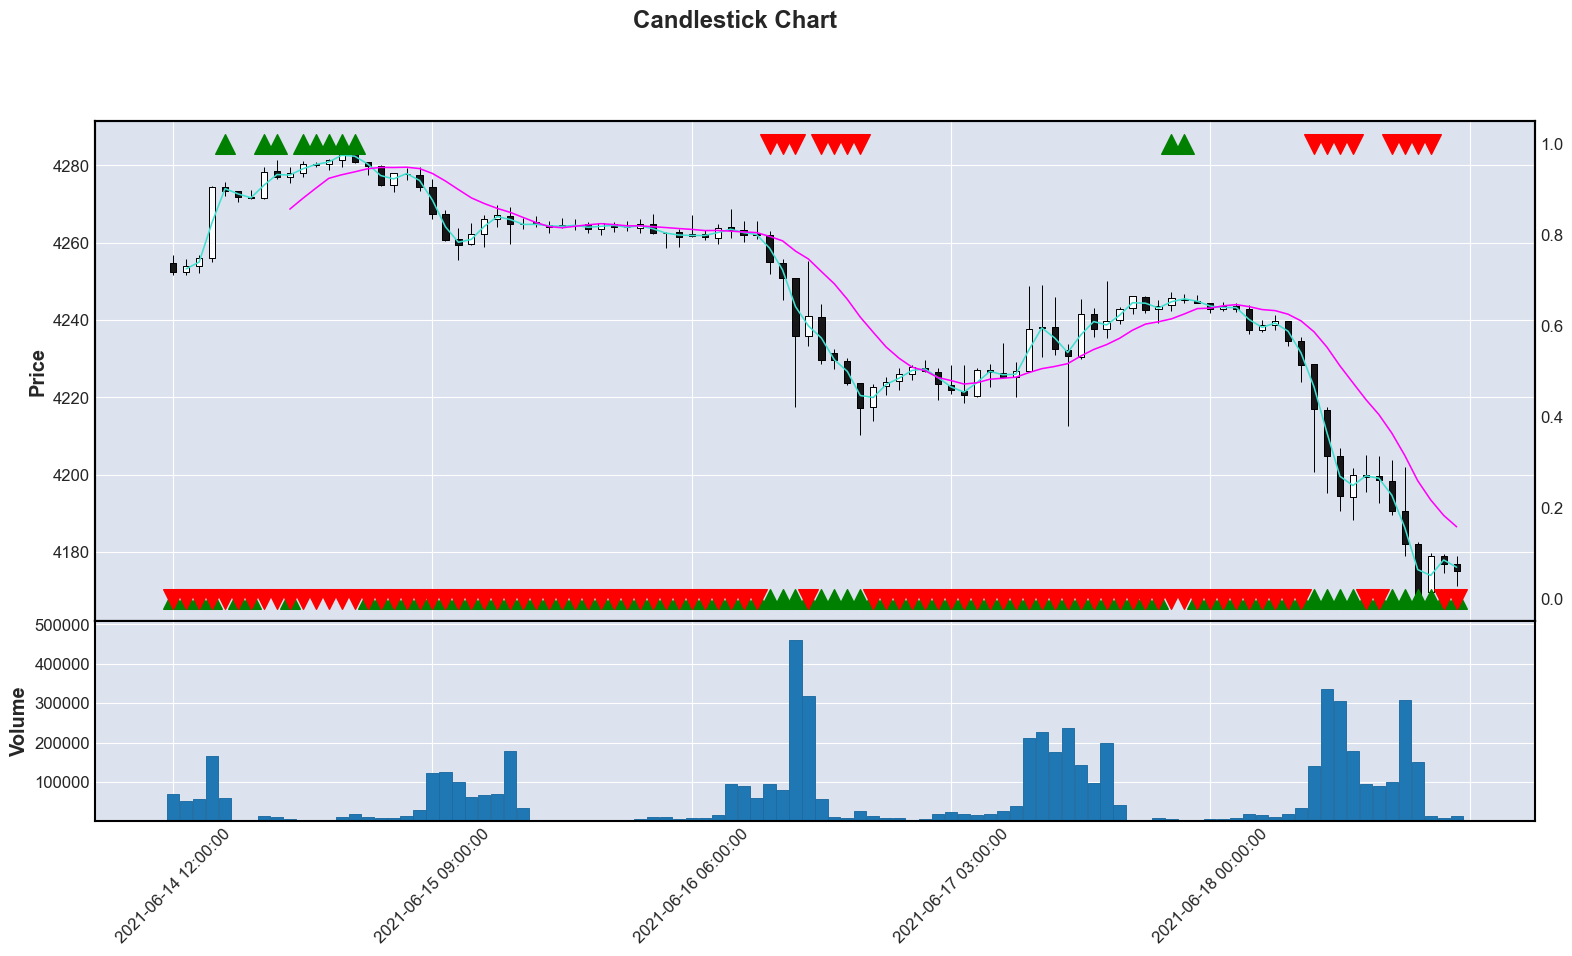

In [29]:
# This code obviously needs some work


columns = ['Open', 'High', 'Low', 'Close', 'Volume']

# Create the candlestick chart using the mpf.plot function
mpf.plot(
    subset_dict[subset][columns], 
    mav=(2,10), 
    volume = True, 
    datetime_format='%Y-%m-%d %H:%M:%S', 
    type='candle', 
    title='Candlestick Chart',
    figsize = (20,10),
    addplot=[
        mpf.make_addplot(subset_dict[subset]['peak'] == 1, type='scatter', color='green', markersize=200, marker='^'),
        mpf.make_addplot(subset_dict[subset]['trough'] == -1, type='scatter', color='red', markersize=200, marker='v')
    ]
)


In [30]:
ES

,Open,High,Low,Close,Volume,Day,candle_average,1_lma,2_lma,3_lma,...,50_lma 50_sma signal,Day_shift,ca_shift,ca_slope,open_shift,open_slope,rolling_high,rolling_low,peak,trough
Date,,,,,,,,,,,,,,,,,,,,,
2005-09-08 17:00:00,1143.25,1143.50,1143.00,1143.00,882,50,1143.1875,1143.25,1143.875,1143.666667,...,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0
2005-09-08 18:00:00,1143.00,1143.75,1143.00,1143.75,757,51,1143.3750,1143.00,1143.125,1143.583333,...,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0
2005-09-08 19:00:00,1144.00,1144.00,1143.50,1143.50,177,52,1143.7500,1144.00,1143.500,1143.416667,...,0,50.0,1143.1875,0.28125,1143.25,0.375,NaN,NaN,0,0
2005-09-08 20:00:00,1143.75,1144.25,1143.50,1144.00,173,53,1143.8750,1143.75,1143.875,1143.583333,...,0,51.0,1143.3750,0.25000,1143.00,0.375,NaN,NaN,0,0
2005-09-08 21:00:00,1144.00,1144.25,1143.75,1144.25,193,54,1144.0625,1144.00,1143.875,1143.916667,...,0,52.0,1143.7500,0.15625,1144.00,0.000,NaN,NaN,0,0
2005-09-08 22:00:00,1144.00,1144.25,1143.75,1143.75,215,55,1143.9375,1144.00,1144.000,1143.916667,...,0,53.0,1143.8750,0.03125,1143.75,0.125,NaN,NaN,0,0
2005-09-08 23:00:00,1144.00,1144.00,1143.50,1143.75,206,56,1143.8125,1144.00,1144.000,1144.000000,...,0,54.0,1144.0625,-0.12500,1144.00,0.000,NaN,NaN,0,0
2005-09-09 00:00:00,1143.75,1144.75,1143.50,1144.25,921,57,1144.0625,1143.75,1143.875,1143.916667,...,0,55.0,1143.9375,0.06250,1144.00,-0.125,NaN,NaN,0,0
2005-09-09 01:00:00,1144.25,1144.50,1143.75,1144.00,341,58,1144.1250,1144.25,1144.000,1144.000000,...,0,56.0,1143.8125,0.15625,1144.00,0.125,NaN,NaN,0,0


# Weighted Moving Average Iteration

### Defining functions for both the fast WMA and slow WMA. This was only necessary due to the naming of the columns.

In [31]:
data = ESw['Open']

def weighted_moving_average(data, period):
    
    weights = []
    weights_calc = []

    for i in range(period + 1) :
        pd.to_numeric(weights_calc.append(i))
    for i in weights_calc :
        weights.append(i/sum(weights_calc))   
    weights.pop(0)
    
    wma = []
    for i in range(len(data) - period + 1):
        wma.append(sum(data[i:i+period] * weights) / sum(weights))
#     return wma
    wma = [float('nan')] * (period - 1) + wma
    ESw[f"{period}_lwma"] = wma
    
def weighted_moving_average_s(data, period):
    
    weights = []
    weights_calc = []

    for i in range(period + 1) :
        pd.to_numeric(weights_calc.append(i))
    for i in weights_calc :
        weights.append(i/sum(weights_calc))   
    weights.pop(0)
    
    wma = []
    for i in range(len(data) - period + 1):
        wma.append(sum(data[i:i+period] * weights) / sum(weights))
#     return wma
    wma = [float('nan')] * (period - 1) + wma
    ESw[f"{period}_swma"] = wma

#### Applying the functions to the weighted data set and creating a defrag copy.

In [32]:
# Just for reference
# LongMAs = list(range(1, 51)) # change this back to 51
# SignalMAs = list(range(1, 51))
# prix_met = 'Open'
# prix_met_2 = 'Close'

for ma in LongMAs :
    weighted_moving_average(data, ma)

for ma in SignalMAs :
    weighted_moving_average_s(data, ma)    

C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\90746750.py:37: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  ESw[f"{period}_swma"] = wma
C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\90746750.py:37: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  ESw[f"{period}_swma"] = wma
C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\90746750.py:37: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once usin

In [33]:
ESw = ESw.copy()
ESw

,Open,High,Low,Close,Volume,Day,candle_average,1_lwma,2_lwma,3_lwma,...,41_swma,42_swma,43_swma,44_swma,45_swma,46_swma,47_swma,48_swma,49_swma,50_swma
Date,,,,,,,,,,,,,,,,,,,,,
2005-09-06 16:00:00,1146.25,1146.75,1146.00,1146.50,1711,1,1146.3750,1146.25,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2005-09-06 17:00:00,1146.25,1146.75,1146.25,1146.50,744,2,1146.4375,1146.25,1146.250000,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2005-09-06 18:00:00,1146.50,1146.75,1146.00,1146.25,395,3,1146.3750,1146.50,1146.416667,1146.375000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2005-09-06 19:00:00,1146.00,1146.25,1146.00,1146.00,280,4,1146.0625,1146.00,1146.166667,1146.208333,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2005-09-06 20:00:00,1146.25,1146.50,1146.00,1146.00,370,5,1146.1875,1146.25,1146.166667,1146.208333,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2005-09-06 21:00:00,1146.25,1146.25,1145.75,1146.00,329,6,1146.0625,1146.25,1146.250000,1146.208333,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2005-09-06 22:00:00,1145.75,1146.25,1145.75,1146.00,312,7,1145.9375,1145.75,1145.916667,1146.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2005-09-06 23:00:00,1146.00,1146.25,1145.50,1145.75,637,8,1145.8750,1146.00,1145.916667,1145.958333,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2005-09-07 00:00:00,1145.50,1146.00,1145.50,1146.00,148,9,1145.7500,1145.50,1145.666667,1145.708333,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [34]:
l_wma_names = []
for period in LongMAs :
    l_wma_names.append(f"{period}_lwma")

s_wma_names = []
for period in SignalMAs :
    s_wma_names.append(f"{period}_swma")

In [35]:
l_wma_names

['1_lwma',
 '2_lwma',
 '3_lwma',
 '4_lwma',
 '5_lwma',
 '6_lwma',
 '7_lwma',
 '8_lwma',
 '9_lwma',
 '10_lwma',
 '11_lwma',
 '12_lwma',
 '13_lwma',
 '14_lwma',
 '15_lwma',
 '16_lwma',
 '17_lwma',
 '18_lwma',
 '19_lwma',
 '20_lwma',
 '21_lwma',
 '22_lwma',
 '23_lwma',
 '24_lwma',
 '25_lwma',
 '26_lwma',
 '27_lwma',
 '28_lwma',
 '29_lwma',
 '30_lwma',
 '31_lwma',
 '32_lwma',
 '33_lwma',
 '34_lwma',
 '35_lwma',
 '36_lwma',
 '37_lwma',
 '38_lwma',
 '39_lwma',
 '40_lwma',
 '41_lwma',
 '42_lwma',
 '43_lwma',
 '44_lwma',
 '45_lwma',
 '46_lwma',
 '47_lwma',
 '48_lwma',
 '49_lwma',
 '50_lwma']

In [36]:
s_wma_names

['1_swma',
 '2_swma',
 '3_swma',
 '4_swma',
 '5_swma',
 '6_swma',
 '7_swma',
 '8_swma',
 '9_swma',
 '10_swma',
 '11_swma',
 '12_swma',
 '13_swma',
 '14_swma',
 '15_swma',
 '16_swma',
 '17_swma',
 '18_swma',
 '19_swma',
 '20_swma',
 '21_swma',
 '22_swma',
 '23_swma',
 '24_swma',
 '25_swma',
 '26_swma',
 '27_swma',
 '28_swma',
 '29_swma',
 '30_swma',
 '31_swma',
 '32_swma',
 '33_swma',
 '34_swma',
 '35_swma',
 '36_swma',
 '37_swma',
 '38_swma',
 '39_swma',
 '40_swma',
 '41_swma',
 '42_swma',
 '43_swma',
 '44_swma',
 '45_swma',
 '46_swma',
 '47_swma',
 '48_swma',
 '49_swma',
 '50_swma']

In [37]:
# This is the hog. It still needs to be changed to weighted
signal_cols_w = []

for lname in l_wma_names :
    for sname in s_wma_names :
#         if pd.to_numeric(re.findall(r'\d+', lname)) > pd.to_numeric(re.findall(r'\d+', sname)) :
        ESw[f"{lname} {sname} signal"] = np.where(ESw[sname] > ESw[lname], 1, 0) #long signal
        ESw[f"{lname} {sname} signal"] = np.where(ESw[sname] < ESw[lname], -1, ESw[f"{lname} {sname} signal"]) #short signal
        ESw.dropna(inplace=True)
        signal_cols_w.append(f"{lname} {sname} signal")

In [38]:
signal_cols_w

['1_lwma 1_swma signal',
 '1_lwma 2_swma signal',
 '1_lwma 3_swma signal',
 '1_lwma 4_swma signal',
 '1_lwma 5_swma signal',
 '1_lwma 6_swma signal',
 '1_lwma 7_swma signal',
 '1_lwma 8_swma signal',
 '1_lwma 9_swma signal',
 '1_lwma 10_swma signal',
 '1_lwma 11_swma signal',
 '1_lwma 12_swma signal',
 '1_lwma 13_swma signal',
 '1_lwma 14_swma signal',
 '1_lwma 15_swma signal',
 '1_lwma 16_swma signal',
 '1_lwma 17_swma signal',
 '1_lwma 18_swma signal',
 '1_lwma 19_swma signal',
 '1_lwma 20_swma signal',
 '1_lwma 21_swma signal',
 '1_lwma 22_swma signal',
 '1_lwma 23_swma signal',
 '1_lwma 24_swma signal',
 '1_lwma 25_swma signal',
 '1_lwma 26_swma signal',
 '1_lwma 27_swma signal',
 '1_lwma 28_swma signal',
 '1_lwma 29_swma signal',
 '1_lwma 30_swma signal',
 '1_lwma 31_swma signal',
 '1_lwma 32_swma signal',
 '1_lwma 33_swma signal',
 '1_lwma 34_swma signal',
 '1_lwma 35_swma signal',
 '1_lwma 36_swma signal',
 '1_lwma 37_swma signal',
 '1_lwma 38_swma signal',
 '1_lwma 39_swma sign

In [39]:
ESw = ESw.copy()
ESw

,Open,High,Low,Close,Volume,Day,candle_average,1_lwma,2_lwma,3_lwma,...,50_lwma 41_swma signal,50_lwma 42_swma signal,50_lwma 43_swma signal,50_lwma 44_swma signal,50_lwma 45_swma signal,50_lwma 46_swma signal,50_lwma 47_swma signal,50_lwma 48_swma signal,50_lwma 49_swma signal,50_lwma 50_swma signal
Date,,,,,,,,,,,,,,,,,,,,,
2005-09-08 17:00:00,1143.25,1143.50,1143.00,1143.00,882,50,1143.1875,1143.25,1143.666667,1143.666667,...,-1,-1,-1,-1,-1,-1,-1,-1,-1,0
2005-09-08 18:00:00,1143.00,1143.75,1143.00,1143.75,757,51,1143.3750,1143.00,1143.083333,1143.333333,...,-1,-1,-1,-1,-1,-1,-1,-1,-1,0
2005-09-08 19:00:00,1144.00,1144.00,1143.50,1143.50,177,52,1143.7500,1144.00,1143.666667,1143.541667,...,-1,-1,-1,-1,-1,-1,-1,-1,-1,0
2005-09-08 20:00:00,1143.75,1144.25,1143.50,1144.00,173,53,1143.8750,1143.75,1143.833333,1143.708333,...,-1,-1,-1,-1,-1,-1,-1,-1,-1,0
2005-09-08 21:00:00,1144.00,1144.25,1143.75,1144.25,193,54,1144.0625,1144.00,1143.916667,1143.916667,...,-1,-1,-1,-1,-1,-1,-1,-1,-1,0
2005-09-08 22:00:00,1144.00,1144.25,1143.75,1143.75,215,55,1143.9375,1144.00,1144.000000,1143.958333,...,-1,-1,-1,-1,-1,-1,-1,-1,-1,0
2005-09-08 23:00:00,1144.00,1144.00,1143.50,1143.75,206,56,1143.8125,1144.00,1144.000000,1144.000000,...,-1,-1,-1,-1,-1,-1,-1,-1,-1,0
2005-09-09 00:00:00,1143.75,1144.75,1143.50,1144.25,921,57,1144.0625,1143.75,1143.833333,1143.875000,...,-1,-1,-1,-1,-1,-1,-1,-1,-1,0
2005-09-09 01:00:00,1144.25,1144.50,1143.75,1144.00,341,58,1144.1250,1144.25,1144.083333,1144.041667,...,-1,-1,-1,-1,-1,-1,-1,-1,-1,0


# Exponential Moving Average

In [40]:
def exponential_moving_average(data, column_name, period):
    """
    There could be something weird about this function.
    Frustratingly, it returns a number of values that is one less than
    the other two moving averages. May need to investigate, but keep
    moving for now.
    
    """
    # Calculate the weighting multiplier
    alpha = 2 / (period + 1)

    # Calculate the initial EMA value using a simple moving average
    sma = data[column_name].rolling(window=period, min_periods=period).mean()
    ema_init = sma[period-1]
    
    # Calculate the EMA values for the remaining data
    ema_values = []
    for i in range(period, len(data)):
        ema = alpha * data[column_name][i] + (1 - alpha) * ema_init
        ema_init = ema
        ema_values.append(ema)

    ema_values = [float('nan')] * (period) + ema_values
    data[f"{period}_lema"] = ema_values

In [41]:
def exponential_moving_average_s(data, column_name, period):
    """
    There could be something weird about this function.
    Frustratingly, it returns a number of values that is one less than
    the other two moving averages. May need to investigate, but keep
    moving for now.
    
    """
    # Calculate the weighting multiplier
    alpha = 2 / (period + 1)

    # Calculate the initial EMA value using a simple moving average
    sma = data[column_name].rolling(window=period, min_periods=period).mean()
    ema_init = sma[period-1]
    
    # Calculate the EMA values for the remaining data
    ema_values = []
    for i in range(period, len(data)):
        ema = alpha * data[column_name][i] + (1 - alpha) * ema_init
        ema_init = ema
        ema_values.append(ema)

    ema_values = [float('nan')] * (period) + ema_values
    data[f"{period}_sema"] = ema_values

In [42]:
# Just for reference
# LongMAs = list(range(1, 51)) # change this back to 51
# SignalMAs = list(range(1, 51))
# prix_met = 'Open'
# prix_met_2 = 'Close'

for ma in LongMAs :
    exponential_moving_average_s(ESe, 'Open', ma)

for ma in SignalMAs :
    exponential_moving_average(ESe, 'Open', ma) 

C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\840976842.py:24: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  data[f"{period}_lema"] = ema_values
C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\840976842.py:24: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  data[f"{period}_lema"] = ema_values
C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\840976842.py:24: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all c

In [43]:
ESe = ESe.copy()
ESe

,Open,High,Low,Close,Volume,Day,candle_average,1_sema,2_sema,3_sema,...,41_lema,42_lema,43_lema,44_lema,45_lema,46_lema,47_lema,48_lema,49_lema,50_lema
Date,,,,,,,,,,,,,,,,,,,,,
2005-09-06 16:00:00,1146.25,1146.75,1146.00,1146.50,1711,1,1146.3750,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2005-09-06 17:00:00,1146.25,1146.75,1146.25,1146.50,744,2,1146.4375,1146.25,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2005-09-06 18:00:00,1146.50,1146.75,1146.00,1146.25,395,3,1146.3750,1146.50,1146.416667,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2005-09-06 19:00:00,1146.00,1146.25,1146.00,1146.00,280,4,1146.0625,1146.00,1146.138889,1146.166667,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2005-09-06 20:00:00,1146.25,1146.50,1146.00,1146.00,370,5,1146.1875,1146.25,1146.212963,1146.208333,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2005-09-06 21:00:00,1146.25,1146.25,1145.75,1146.00,329,6,1146.0625,1146.25,1146.237654,1146.229167,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2005-09-06 22:00:00,1145.75,1146.25,1145.75,1146.00,312,7,1145.9375,1145.75,1145.912551,1145.989583,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2005-09-06 23:00:00,1146.00,1146.25,1145.50,1145.75,637,8,1145.8750,1146.00,1145.970850,1145.994792,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2005-09-07 00:00:00,1145.50,1146.00,1145.50,1146.00,148,9,1145.7500,1145.50,1145.656950,1145.747396,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [44]:
l_ema_names = []
for period in LongMAs :
    l_ema_names.append(f"{period}_lema")

s_ema_names = []
for period in SignalMAs :
    s_ema_names.append(f"{period}_sema")

In [45]:
l_ema_names

['1_lema',
 '2_lema',
 '3_lema',
 '4_lema',
 '5_lema',
 '6_lema',
 '7_lema',
 '8_lema',
 '9_lema',
 '10_lema',
 '11_lema',
 '12_lema',
 '13_lema',
 '14_lema',
 '15_lema',
 '16_lema',
 '17_lema',
 '18_lema',
 '19_lema',
 '20_lema',
 '21_lema',
 '22_lema',
 '23_lema',
 '24_lema',
 '25_lema',
 '26_lema',
 '27_lema',
 '28_lema',
 '29_lema',
 '30_lema',
 '31_lema',
 '32_lema',
 '33_lema',
 '34_lema',
 '35_lema',
 '36_lema',
 '37_lema',
 '38_lema',
 '39_lema',
 '40_lema',
 '41_lema',
 '42_lema',
 '43_lema',
 '44_lema',
 '45_lema',
 '46_lema',
 '47_lema',
 '48_lema',
 '49_lema',
 '50_lema']

In [46]:
s_ema_names

['1_sema',
 '2_sema',
 '3_sema',
 '4_sema',
 '5_sema',
 '6_sema',
 '7_sema',
 '8_sema',
 '9_sema',
 '10_sema',
 '11_sema',
 '12_sema',
 '13_sema',
 '14_sema',
 '15_sema',
 '16_sema',
 '17_sema',
 '18_sema',
 '19_sema',
 '20_sema',
 '21_sema',
 '22_sema',
 '23_sema',
 '24_sema',
 '25_sema',
 '26_sema',
 '27_sema',
 '28_sema',
 '29_sema',
 '30_sema',
 '31_sema',
 '32_sema',
 '33_sema',
 '34_sema',
 '35_sema',
 '36_sema',
 '37_sema',
 '38_sema',
 '39_sema',
 '40_sema',
 '41_sema',
 '42_sema',
 '43_sema',
 '44_sema',
 '45_sema',
 '46_sema',
 '47_sema',
 '48_sema',
 '49_sema',
 '50_sema']

In [47]:
# This is the hog
signal_cols_e = []

for lname in l_ema_names :
    for sname in s_ema_names :
#         if pd.to_numeric(re.findall(r'\d+', lname)) > pd.to_numeric(re.findall(r'\d+', sname)) :
        ESe[f"{lname} {sname} signal"] = np.where(ESe[sname] > ESe[lname], 1, 0) #long signal
        ESe[f"{lname} {sname} signal"] = np.where(ESe[sname] < ESe[lname], -1, ESe[f"{lname} {sname} signal"]) #short signal
        ESe.dropna(inplace=True)
        signal_cols_e.append(f"{lname} {sname} signal")

In [48]:
ESe = ESe.copy()
ESe

,Open,High,Low,Close,Volume,Day,candle_average,1_sema,2_sema,3_sema,...,50_lema 41_sema signal,50_lema 42_sema signal,50_lema 43_sema signal,50_lema 44_sema signal,50_lema 45_sema signal,50_lema 46_sema signal,50_lema 47_sema signal,50_lema 48_sema signal,50_lema 49_sema signal,50_lema 50_sema signal
Date,,,,,,,,,,,,,,,,,,,,,
2005-09-08 18:00:00,1143.00,1143.75,1143.00,1143.75,757,51,1143.3750,1143.00,1143.200724,1143.404726,...,1,1,1,1,1,1,-1,1,-1,0
2005-09-08 19:00:00,1144.00,1144.00,1143.50,1143.50,177,52,1143.7500,1144.00,1143.733575,1143.702363,...,1,1,1,1,1,1,-1,1,-1,0
2005-09-08 20:00:00,1143.75,1144.25,1143.50,1144.00,173,53,1143.8750,1143.75,1143.744525,1143.726181,...,1,1,1,1,1,1,-1,1,-1,0
2005-09-08 21:00:00,1144.00,1144.25,1143.75,1144.25,193,54,1144.0625,1144.00,1143.914842,1143.863091,...,1,1,1,1,1,1,-1,1,-1,0
2005-09-08 22:00:00,1144.00,1144.25,1143.75,1143.75,215,55,1143.9375,1144.00,1143.971614,1143.931545,...,1,1,1,1,1,1,-1,1,-1,0
2005-09-08 23:00:00,1144.00,1144.00,1143.50,1143.75,206,56,1143.8125,1144.00,1143.990538,1143.965773,...,1,1,1,1,1,1,-1,1,-1,0
2005-09-09 00:00:00,1143.75,1144.75,1143.50,1144.25,921,57,1144.0625,1143.75,1143.830179,1143.857886,...,1,1,1,1,1,1,-1,1,-1,0
2005-09-09 01:00:00,1144.25,1144.50,1143.75,1144.00,341,58,1144.1250,1144.25,1144.110060,1144.053943,...,1,1,1,1,1,1,-1,1,-1,0
2005-09-09 02:00:00,1144.00,1145.75,1144.00,1145.25,1771,59,1144.7500,1144.00,1144.036687,1144.026972,...,1,1,1,1,1,1,1,1,-1,0


# Profit Calculations

### The following code uses my own methods for calculating profit based on point accrual.

In [49]:
#running this code more than once in the kernal screws up the affected columns; 
#need to move the signal down one row with shift() if we use Open to Open differences
#could also possibly shift point_profit

# for sig_col in signal_cols :
#     ES[sig_col] = ES[sig_col].shift()

In [50]:
ES['movement'] = ES['Open'].diff().shift(-1) #this line calculates movement from Open to Open
ESw['movement'] = ESw['Open'].diff().shift(-1)
ESe['movement'] = ESe['Open'].diff().shift(-1)
#ES['movement'] = ES['Close'] - ES['Open']

In [51]:
profit_cols = []
for sig_col in signal_cols :
    ES[f"{sig_col} point profit"] = ES['movement']*ES[sig_col]
    profit_cols.append(f"{sig_col} point profit")
    
ES.dropna(inplace=True) #drops records that we can't really use

C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1635903176.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  ES[f"{sig_col} point profit"] = ES['movement']*ES[sig_col]
C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1635903176.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  ES[f"{sig_col} point profit"] = ES['movement']*ES[sig_col]
C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1635903176.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which

C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1635903176.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  ES[f"{sig_col} point profit"] = ES['movement']*ES[sig_col]
C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1635903176.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  ES[f"{sig_col} point profit"] = ES['movement']*ES[sig_col]
C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1635903176.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which

C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1635903176.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  ES[f"{sig_col} point profit"] = ES['movement']*ES[sig_col]
C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1635903176.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  ES[f"{sig_col} point profit"] = ES['movement']*ES[sig_col]
C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1635903176.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which

C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1635903176.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  ES[f"{sig_col} point profit"] = ES['movement']*ES[sig_col]
C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1635903176.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  ES[f"{sig_col} point profit"] = ES['movement']*ES[sig_col]
C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1635903176.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which

C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1635903176.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  ES[f"{sig_col} point profit"] = ES['movement']*ES[sig_col]
C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1635903176.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  ES[f"{sig_col} point profit"] = ES['movement']*ES[sig_col]
C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1635903176.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which

C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1635903176.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  ES[f"{sig_col} point profit"] = ES['movement']*ES[sig_col]
C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1635903176.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  ES[f"{sig_col} point profit"] = ES['movement']*ES[sig_col]
C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1635903176.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which

... (58 outputs left out)

C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1635903176.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  ES[f"{sig_col} point profit"] = ES['movement']*ES[sig_col]
C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1635903176.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  ES[f"{sig_col} point profit"] = ES['movement']*ES[sig_col]
C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1635903176.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which

C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1635903176.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  ES[f"{sig_col} point profit"] = ES['movement']*ES[sig_col]
C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1635903176.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  ES[f"{sig_col} point profit"] = ES['movement']*ES[sig_col]
C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1635903176.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which

C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1635903176.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  ES[f"{sig_col} point profit"] = ES['movement']*ES[sig_col]
C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1635903176.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  ES[f"{sig_col} point profit"] = ES['movement']*ES[sig_col]
C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1635903176.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which

C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1635903176.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  ES[f"{sig_col} point profit"] = ES['movement']*ES[sig_col]
C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1635903176.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  ES[f"{sig_col} point profit"] = ES['movement']*ES[sig_col]
C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1635903176.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which

In [52]:
profit_cols_w = []
for sig_col in signal_cols_w :
    ESw[f"{sig_col} point profit"] = ESw['movement']*ESw[sig_col]
    profit_cols_w.append(f"{sig_col} point profit")
    
ESw.dropna(inplace=True) #drops records that we can't really use

C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1789931044.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  ESw[f"{sig_col} point profit"] = ESw['movement']*ESw[sig_col]
C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1789931044.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  ESw[f"{sig_col} point profit"] = ESw['movement']*ESw[sig_col]
C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1789931044.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times,

C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1789931044.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  ESw[f"{sig_col} point profit"] = ESw['movement']*ESw[sig_col]
C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1789931044.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  ESw[f"{sig_col} point profit"] = ESw['movement']*ESw[sig_col]
C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1789931044.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times,

C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1789931044.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  ESw[f"{sig_col} point profit"] = ESw['movement']*ESw[sig_col]
C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1789931044.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  ESw[f"{sig_col} point profit"] = ESw['movement']*ESw[sig_col]
C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1789931044.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times,

C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1789931044.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  ESw[f"{sig_col} point profit"] = ESw['movement']*ESw[sig_col]
C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1789931044.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  ESw[f"{sig_col} point profit"] = ESw['movement']*ESw[sig_col]
C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1789931044.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times,

C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1789931044.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  ESw[f"{sig_col} point profit"] = ESw['movement']*ESw[sig_col]
C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1789931044.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  ESw[f"{sig_col} point profit"] = ESw['movement']*ESw[sig_col]
C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1789931044.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times,

C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1789931044.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  ESw[f"{sig_col} point profit"] = ESw['movement']*ESw[sig_col]
C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1789931044.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  ESw[f"{sig_col} point profit"] = ESw['movement']*ESw[sig_col]
C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1789931044.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times,

... (57 outputs left out)

C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1789931044.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  ESw[f"{sig_col} point profit"] = ESw['movement']*ESw[sig_col]
C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1789931044.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  ESw[f"{sig_col} point profit"] = ESw['movement']*ESw[sig_col]
C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1789931044.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times,

C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1789931044.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  ESw[f"{sig_col} point profit"] = ESw['movement']*ESw[sig_col]
C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1789931044.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  ESw[f"{sig_col} point profit"] = ESw['movement']*ESw[sig_col]
C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1789931044.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times,

C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1789931044.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  ESw[f"{sig_col} point profit"] = ESw['movement']*ESw[sig_col]
C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1789931044.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  ESw[f"{sig_col} point profit"] = ESw['movement']*ESw[sig_col]
C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1789931044.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times,

C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1789931044.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  ESw[f"{sig_col} point profit"] = ESw['movement']*ESw[sig_col]
C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1789931044.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  ESw[f"{sig_col} point profit"] = ESw['movement']*ESw[sig_col]
C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1789931044.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times,

In [53]:
profit_cols_e = []
for sig_col in signal_cols_e :
    ESe[f"{sig_col} point profit"] = ESe['movement']*ESe[sig_col]
    profit_cols_e.append(f"{sig_col} point profit")
    
ESe.dropna(inplace=True) #drops records that we can't really use

C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1008099281.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  ESe[f"{sig_col} point profit"] = ESe['movement']*ESe[sig_col]
C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1008099281.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  ESe[f"{sig_col} point profit"] = ESe['movement']*ESe[sig_col]
C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1008099281.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times,

C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1008099281.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  ESe[f"{sig_col} point profit"] = ESe['movement']*ESe[sig_col]
C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1008099281.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  ESe[f"{sig_col} point profit"] = ESe['movement']*ESe[sig_col]
C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1008099281.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times,

C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1008099281.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  ESe[f"{sig_col} point profit"] = ESe['movement']*ESe[sig_col]
C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1008099281.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  ESe[f"{sig_col} point profit"] = ESe['movement']*ESe[sig_col]
C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1008099281.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times,

C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1008099281.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  ESe[f"{sig_col} point profit"] = ESe['movement']*ESe[sig_col]
C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1008099281.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  ESe[f"{sig_col} point profit"] = ESe['movement']*ESe[sig_col]
C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1008099281.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times,

C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1008099281.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  ESe[f"{sig_col} point profit"] = ESe['movement']*ESe[sig_col]
C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1008099281.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  ESe[f"{sig_col} point profit"] = ESe['movement']*ESe[sig_col]
C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1008099281.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times,

C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1008099281.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  ESe[f"{sig_col} point profit"] = ESe['movement']*ESe[sig_col]
C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1008099281.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  ESe[f"{sig_col} point profit"] = ESe['movement']*ESe[sig_col]
C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1008099281.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times,

... (58 outputs left out)

C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1008099281.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  ESe[f"{sig_col} point profit"] = ESe['movement']*ESe[sig_col]
C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1008099281.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  ESe[f"{sig_col} point profit"] = ESe['movement']*ESe[sig_col]
C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1008099281.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times,

C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1008099281.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  ESe[f"{sig_col} point profit"] = ESe['movement']*ESe[sig_col]
C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1008099281.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  ESe[f"{sig_col} point profit"] = ESe['movement']*ESe[sig_col]
C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1008099281.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times,

C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1008099281.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  ESe[f"{sig_col} point profit"] = ESe['movement']*ESe[sig_col]
C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1008099281.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  ESe[f"{sig_col} point profit"] = ESe['movement']*ESe[sig_col]
C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1008099281.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times,

C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1008099281.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  ESe[f"{sig_col} point profit"] = ESe['movement']*ESe[sig_col]
C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1008099281.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  ESe[f"{sig_col} point profit"] = ESe['movement']*ESe[sig_col]
C:\Users\rsmcd\AppData\Local\Temp\ipykernel_13508\1008099281.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times,

In [54]:
profit_cols
# signal_cols
# ES

['1_lma 1_sma signal point profit',
 '1_lma 2_sma signal point profit',
 '1_lma 3_sma signal point profit',
 '1_lma 4_sma signal point profit',
 '1_lma 5_sma signal point profit',
 '1_lma 6_sma signal point profit',
 '1_lma 7_sma signal point profit',
 '1_lma 8_sma signal point profit',
 '1_lma 9_sma signal point profit',
 '1_lma 10_sma signal point profit',
 '1_lma 11_sma signal point profit',
 '1_lma 12_sma signal point profit',
 '1_lma 13_sma signal point profit',
 '1_lma 14_sma signal point profit',
 '1_lma 15_sma signal point profit',
 '1_lma 16_sma signal point profit',
 '1_lma 17_sma signal point profit',
 '1_lma 18_sma signal point profit',
 '1_lma 19_sma signal point profit',
 '1_lma 20_sma signal point profit',
 '1_lma 21_sma signal point profit',
 '1_lma 22_sma signal point profit',
 '1_lma 23_sma signal point profit',
 '1_lma 24_sma signal point profit',
 '1_lma 25_sma signal point profit',
 '1_lma 26_sma signal point profit',
 '1_lma 27_sma signal point profit',
 '1_lma 28

In [55]:
profit_cols_w

['1_lwma 1_swma signal point profit',
 '1_lwma 2_swma signal point profit',
 '1_lwma 3_swma signal point profit',
 '1_lwma 4_swma signal point profit',
 '1_lwma 5_swma signal point profit',
 '1_lwma 6_swma signal point profit',
 '1_lwma 7_swma signal point profit',
 '1_lwma 8_swma signal point profit',
 '1_lwma 9_swma signal point profit',
 '1_lwma 10_swma signal point profit',
 '1_lwma 11_swma signal point profit',
 '1_lwma 12_swma signal point profit',
 '1_lwma 13_swma signal point profit',
 '1_lwma 14_swma signal point profit',
 '1_lwma 15_swma signal point profit',
 '1_lwma 16_swma signal point profit',
 '1_lwma 17_swma signal point profit',
 '1_lwma 18_swma signal point profit',
 '1_lwma 19_swma signal point profit',
 '1_lwma 20_swma signal point profit',
 '1_lwma 21_swma signal point profit',
 '1_lwma 22_swma signal point profit',
 '1_lwma 23_swma signal point profit',
 '1_lwma 24_swma signal point profit',
 '1_lwma 25_swma signal point profit',
 '1_lwma 26_swma signal point prof

In [56]:
profit_cols_e

['1_lema 1_sema signal point profit',
 '1_lema 2_sema signal point profit',
 '1_lema 3_sema signal point profit',
 '1_lema 4_sema signal point profit',
 '1_lema 5_sema signal point profit',
 '1_lema 6_sema signal point profit',
 '1_lema 7_sema signal point profit',
 '1_lema 8_sema signal point profit',
 '1_lema 9_sema signal point profit',
 '1_lema 10_sema signal point profit',
 '1_lema 11_sema signal point profit',
 '1_lema 12_sema signal point profit',
 '1_lema 13_sema signal point profit',
 '1_lema 14_sema signal point profit',
 '1_lema 15_sema signal point profit',
 '1_lema 16_sema signal point profit',
 '1_lema 17_sema signal point profit',
 '1_lema 18_sema signal point profit',
 '1_lema 19_sema signal point profit',
 '1_lema 20_sema signal point profit',
 '1_lema 21_sema signal point profit',
 '1_lema 22_sema signal point profit',
 '1_lema 23_sema signal point profit',
 '1_lema 24_sema signal point profit',
 '1_lema 25_sema signal point profit',
 '1_lema 26_sema signal point prof

In [57]:
#number of e-mini contracts traded (one micro is one tenth of an e-mini, a full contract is five e-minis)
#full value: $250
#e-mini value: $50
#micro value: $5

contracts = 1
point_value = 50

#buy/hold futures dollars
dollars_bh = ((ES[prix_met][-1])-(ES[prix_met][0]))*point_value*contracts #multiply difference of now and then by $50/pt/contract
dollars_bh = "${:.2f}".format(dollars_bh) #format the result in dollars

#system futures dollars
profit_totals = []
for prof_col in profit_cols :
    profit_totals.append(ES[prof_col].sum()*point_value*contracts)
    
    print('Returns for '+prof_col.replace(' signal point profit', '')+ ' Strategy')
    print("${:.2f}".format(ES[prof_col].sum()*point_value*contracts))
    print()
# print('Buy and Hold Strategy Returns')
# print(dollars_bh)     

Returns for 1_lma 1_sma Strategy
$0.00

Returns for 1_lma 2_sma Strategy
$177225.00

Returns for 1_lma 3_sma Strategy
$87212.50

Returns for 1_lma 4_sma Strategy
$117787.50

Returns for 1_lma 5_sma Strategy
$156950.00

Returns for 1_lma 6_sma Strategy
$96912.50

Returns for 1_lma 7_sma Strategy
$51150.00

Returns for 1_lma 8_sma Strategy
$14912.50

Returns for 1_lma 9_sma Strategy
$37300.00

Returns for 1_lma 10_sma Strategy
$54975.00

Returns for 1_lma 11_sma Strategy
$97900.00

Returns for 1_lma 12_sma Strategy
$111000.00

Returns for 1_lma 13_sma Strategy
$134550.00

Returns for 1_lma 14_sma Strategy
$153337.50

Returns for 1_lma 15_sma Strategy
$170075.00

Returns for 1_lma 16_sma Strategy
$150425.00

Returns for 1_lma 17_sma Strategy
$134337.50

Returns for 1_lma 18_sma Strategy
$134100.00

Returns for 1_lma 19_sma Strategy
$121362.50

Returns for 1_lma 20_sma Strategy
$147112.50

Returns for 1_lma 21_sma Strategy
$121337.50

Returns for 1_lma 22_sma Strategy
$93350.00

Returns fo

Returns for 6_lma 20_sma Strategy
$-39187.50

Returns for 6_lma 21_sma Strategy
$-57875.00

Returns for 6_lma 22_sma Strategy
$-84987.50

Returns for 6_lma 23_sma Strategy
$-80862.50

Returns for 6_lma 24_sma Strategy
$-83325.00

Returns for 6_lma 25_sma Strategy
$-85100.00

Returns for 6_lma 26_sma Strategy
$-68250.00

Returns for 6_lma 27_sma Strategy
$-80987.50

Returns for 6_lma 28_sma Strategy
$-98162.50

Returns for 6_lma 29_sma Strategy
$-102737.50

Returns for 6_lma 30_sma Strategy
$-65650.00

Returns for 6_lma 31_sma Strategy
$-51925.00

Returns for 6_lma 32_sma Strategy
$-28312.50

Returns for 6_lma 33_sma Strategy
$-41212.50

Returns for 6_lma 34_sma Strategy
$-30150.00

Returns for 6_lma 35_sma Strategy
$-12737.50

Returns for 6_lma 36_sma Strategy
$37850.00

Returns for 6_lma 37_sma Strategy
$34087.50

Returns for 6_lma 38_sma Strategy
$19687.50

Returns for 6_lma 39_sma Strategy
$17862.50

Returns for 6_lma 40_sma Strategy
$27475.00

Returns for 6_lma 41_sma Strategy
$400

$81575.00

Returns for 11_lma 48_sma Strategy
$78212.50

Returns for 11_lma 49_sma Strategy
$57412.50

Returns for 11_lma 50_sma Strategy
$55950.00

Returns for 12_lma 1_sma Strategy
$-111000.00

Returns for 12_lma 2_sma Strategy
$-115100.00

Returns for 12_lma 3_sma Strategy
$-59812.50

Returns for 12_lma 4_sma Strategy
$29125.00

Returns for 12_lma 5_sma Strategy
$4125.00

Returns for 12_lma 6_sma Strategy
$-24600.00

Returns for 12_lma 7_sma Strategy
$-14425.00

Returns for 12_lma 8_sma Strategy
$-51750.00

Returns for 12_lma 9_sma Strategy
$46350.00

Returns for 12_lma 10_sma Strategy
$69425.00

Returns for 12_lma 11_sma Strategy
$50800.00

Returns for 12_lma 12_sma Strategy
$0.00

Returns for 12_lma 13_sma Strategy
$166200.00

Returns for 12_lma 14_sma Strategy
$138725.00

Returns for 12_lma 15_sma Strategy
$75750.00

Returns for 12_lma 16_sma Strategy
$-8162.50

Returns for 12_lma 17_sma Strategy
$-45625.00

Returns for 12_lma 18_sma Strategy
$-69887.50

Returns for 12_lma 19_sma

Returns for 18_lma 16_sma Strategy
$161775.00

Returns for 18_lma 17_sma Strategy
$152725.00

Returns for 18_lma 18_sma Strategy
$0.00

Returns for 18_lma 19_sma Strategy
$-33312.50

Returns for 18_lma 20_sma Strategy
$-135037.50

Returns for 18_lma 21_sma Strategy
$-130987.50

Returns for 18_lma 22_sma Strategy
$-135075.00

Returns for 18_lma 23_sma Strategy
$-120762.50

Returns for 18_lma 24_sma Strategy
$-78537.50

Returns for 18_lma 25_sma Strategy
$-41625.00

Returns for 18_lma 26_sma Strategy
$-32787.50

Returns for 18_lma 27_sma Strategy
$80312.50

Returns for 18_lma 28_sma Strategy
$99062.50

Returns for 18_lma 29_sma Strategy
$118212.50

Returns for 18_lma 30_sma Strategy
$135150.00

Returns for 18_lma 31_sma Strategy
$138700.00

Returns for 18_lma 32_sma Strategy
$173350.00

Returns for 18_lma 33_sma Strategy
$161875.00

Returns for 18_lma 34_sma Strategy
$166650.00

Returns for 18_lma 35_sma Strategy
$164550.00

Returns for 18_lma 36_sma Strategy
$160200.00

Returns for 18_l

Returns for 24_lma 42_sma Strategy
$136512.50

Returns for 24_lma 43_sma Strategy
$98512.50

Returns for 24_lma 44_sma Strategy
$94312.50

Returns for 24_lma 45_sma Strategy
$98950.00

Returns for 24_lma 46_sma Strategy
$77525.00

Returns for 24_lma 47_sma Strategy
$88575.00

Returns for 24_lma 48_sma Strategy
$82562.50

Returns for 24_lma 49_sma Strategy
$95700.00

Returns for 24_lma 50_sma Strategy
$120525.00

Returns for 25_lma 1_sma Strategy
$-57187.50

Returns for 25_lma 2_sma Strategy
$-13812.50

Returns for 25_lma 3_sma Strategy
$39812.50

Returns for 25_lma 4_sma Strategy
$100775.00

Returns for 25_lma 5_sma Strategy
$90600.00

Returns for 25_lma 6_sma Strategy
$85100.00

Returns for 25_lma 7_sma Strategy
$104112.50

Returns for 25_lma 8_sma Strategy
$108737.50

Returns for 25_lma 9_sma Strategy
$79862.50

Returns for 25_lma 10_sma Strategy
$102825.00

Returns for 25_lma 11_sma Strategy
$109975.00

Returns for 25_lma 12_sma Strategy
$123487.50

Returns for 25_lma 13_sma Strateg

Returns for 31_lma 28_sma Strategy
$-154700.00

Returns for 31_lma 29_sma Strategy
$-215037.50

Returns for 31_lma 30_sma Strategy
$-235375.00

Returns for 31_lma 31_sma Strategy
$0.00

Returns for 31_lma 32_sma Strategy
$259700.00

Returns for 31_lma 33_sma Strategy
$249037.50

Returns for 31_lma 34_sma Strategy
$215012.50

Returns for 31_lma 35_sma Strategy
$167950.00

Returns for 31_lma 36_sma Strategy
$132650.00

Returns for 31_lma 37_sma Strategy
$131362.50

Returns for 31_lma 38_sma Strategy
$143425.00

Returns for 31_lma 39_sma Strategy
$140675.00

Returns for 31_lma 40_sma Strategy
$124737.50

Returns for 31_lma 41_sma Strategy
$122275.00

Returns for 31_lma 42_sma Strategy
$99075.00

Returns for 31_lma 43_sma Strategy
$95650.00

Returns for 31_lma 44_sma Strategy
$73475.00

Returns for 31_lma 45_sma Strategy
$45575.00

Returns for 31_lma 46_sma Strategy
$55800.00

Returns for 31_lma 47_sma Strategy
$27225.00

Returns for 31_lma 48_sma Strategy
$44787.50

Returns for 31_lma 49_

Returns for 38_lma 19_sma Strategy
$-156837.50

Returns for 38_lma 20_sma Strategy
$-113812.50

Returns for 38_lma 21_sma Strategy
$-148850.00

Returns for 38_lma 22_sma Strategy
$-170500.00

Returns for 38_lma 23_sma Strategy
$-149725.00

Returns for 38_lma 24_sma Strategy
$-176625.00

Returns for 38_lma 25_sma Strategy
$-210337.50

Returns for 38_lma 26_sma Strategy
$-202950.00

Returns for 38_lma 27_sma Strategy
$-209300.00

Returns for 38_lma 28_sma Strategy
$-179687.50

Returns for 38_lma 29_sma Strategy
$-188162.50

Returns for 38_lma 30_sma Strategy
$-168100.00

Returns for 38_lma 31_sma Strategy
$-143425.00

Returns for 38_lma 32_sma Strategy
$-163187.50

Returns for 38_lma 33_sma Strategy
$-183662.50

Returns for 38_lma 34_sma Strategy
$-146800.00

Returns for 38_lma 35_sma Strategy
$-147437.50

Returns for 38_lma 36_sma Strategy
$-150700.00

Returns for 38_lma 37_sma Strategy
$-148737.50

Returns for 38_lma 38_sma Strategy
$0.00

Returns for 38_lma 39_sma Strategy
$145837.50


Returns for 45_lma 7_sma Strategy
$-66437.50

Returns for 45_lma 8_sma Strategy
$-109387.50

Returns for 45_lma 9_sma Strategy
$-99325.00

Returns for 45_lma 10_sma Strategy
$-106687.50

Returns for 45_lma 11_sma Strategy
$-132362.50

Returns for 45_lma 12_sma Strategy
$-122762.50

Returns for 45_lma 13_sma Strategy
$-64400.00

Returns for 45_lma 14_sma Strategy
$-63050.00

Returns for 45_lma 15_sma Strategy
$-67312.50

Returns for 45_lma 16_sma Strategy
$-82350.00

Returns for 45_lma 17_sma Strategy
$-126525.00

Returns for 45_lma 18_sma Strategy
$-98325.00

Returns for 45_lma 19_sma Strategy
$-48987.50

Returns for 45_lma 20_sma Strategy
$-67212.50

Returns for 45_lma 21_sma Strategy
$-72600.00

Returns for 45_lma 22_sma Strategy
$-104400.00

Returns for 45_lma 23_sma Strategy
$-113587.50

Returns for 45_lma 24_sma Strategy
$-98950.00

Returns for 45_lma 25_sma Strategy
$-79175.00

Returns for 45_lma 26_sma Strategy
$-99562.50

Returns for 45_lma 27_sma Strategy
$-96250.00

Returns f

In [58]:
profit_totals_w = []
for prof_col in profit_cols_w :
    profit_totals_w.append(ESw[prof_col].sum()*point_value*contracts)
    
    print('Returns for '+prof_col.replace(' signal point profit', '')+ ' Strategy')
    print("${:.2f}".format(ESw[prof_col].sum()*point_value*contracts))
    print()

Returns for 1_lwma 1_swma Strategy
$0.00

Returns for 1_lwma 2_swma Strategy
$175662.50

Returns for 1_lwma 3_swma Strategy
$146950.00

Returns for 1_lwma 4_swma Strategy
$112412.50

Returns for 1_lwma 5_swma Strategy
$136137.50

Returns for 1_lwma 6_swma Strategy
$147437.50

Returns for 1_lwma 7_swma Strategy
$119387.50

Returns for 1_lwma 8_swma Strategy
$93562.50

Returns for 1_lwma 9_swma Strategy
$41562.50

Returns for 1_lwma 10_swma Strategy
$-6262.50

Returns for 1_lwma 11_swma Strategy
$-3762.50

Returns for 1_lwma 12_swma Strategy
$25775.00

Returns for 1_lwma 13_swma Strategy
$62237.50

Returns for 1_lwma 14_swma Strategy
$77737.50

Returns for 1_lwma 15_swma Strategy
$84187.50

Returns for 1_lwma 16_swma Strategy
$74137.50

Returns for 1_lwma 17_swma Strategy
$95625.00

Returns for 1_lwma 18_swma Strategy
$114162.50

Returns for 1_lwma 19_swma Strategy
$141175.00

Returns for 1_lwma 20_swma Strategy
$161250.00

Returns for 1_lwma 21_swma Strategy
$124387.50

Returns for 1_lw

$-15200.00

Returns for 7_lwma 1_swma Strategy
$-119387.50

Returns for 7_lwma 2_swma Strategy
$-58175.00

Returns for 7_lwma 3_swma Strategy
$-30512.50

Returns for 7_lwma 4_swma Strategy
$29925.00

Returns for 7_lwma 5_swma Strategy
$15325.00

Returns for 7_lwma 6_swma Strategy
$17762.50

Returns for 7_lwma 7_swma Strategy
$0.00

Returns for 7_lwma 8_swma Strategy
$42900.00

Returns for 7_lwma 9_swma Strategy
$14337.50

Returns for 7_lwma 10_swma Strategy
$41300.00

Returns for 7_lwma 11_swma Strategy
$20675.00

Returns for 7_lwma 12_swma Strategy
$2912.50

Returns for 7_lwma 13_swma Strategy
$36800.00

Returns for 7_lwma 14_swma Strategy
$26387.50

Returns for 7_lwma 15_swma Strategy
$39312.50

Returns for 7_lwma 16_swma Strategy
$11175.00

Returns for 7_lwma 17_swma Strategy
$16275.00

Returns for 7_lwma 18_swma Strategy
$3525.00

Returns for 7_lwma 19_swma Strategy
$41925.00

Returns for 7_lwma 20_swma Strategy
$26587.50

Returns for 7_lwma 21_swma Strategy
$38312.50

Returns for 

Returns for 13_lwma 13_swma Strategy
$0.00

Returns for 13_lwma 14_swma Strategy
$66712.50

Returns for 13_lwma 15_swma Strategy
$32437.50

Returns for 13_lwma 16_swma Strategy
$21837.50

Returns for 13_lwma 17_swma Strategy
$49600.00

Returns for 13_lwma 18_swma Strategy
$44675.00

Returns for 13_lwma 19_swma Strategy
$50500.00

Returns for 13_lwma 20_swma Strategy
$40612.50

Returns for 13_lwma 21_swma Strategy
$21737.50

Returns for 13_lwma 22_swma Strategy
$-3650.00

Returns for 13_lwma 23_swma Strategy
$-6150.00

Returns for 13_lwma 24_swma Strategy
$-18475.00

Returns for 13_lwma 25_swma Strategy
$-8287.50

Returns for 13_lwma 26_swma Strategy
$200.00

Returns for 13_lwma 27_swma Strategy
$-40500.00

Returns for 13_lwma 28_swma Strategy
$-61250.00

Returns for 13_lwma 29_swma Strategy
$-58887.50

Returns for 13_lwma 30_swma Strategy
$-71925.00

Returns for 13_lwma 31_swma Strategy
$-70125.00

Returns for 13_lwma 32_swma Strategy
$-74375.00

Returns for 13_lwma 33_swma Strategy
$-

Returns for 19_lwma 24_swma Strategy
$-74975.00

Returns for 19_lwma 25_swma Strategy
$-89575.00

Returns for 19_lwma 26_swma Strategy
$-110787.50

Returns for 19_lwma 27_swma Strategy
$-109725.00

Returns for 19_lwma 28_swma Strategy
$-91500.00

Returns for 19_lwma 29_swma Strategy
$-75150.00

Returns for 19_lwma 30_swma Strategy
$-44100.00

Returns for 19_lwma 31_swma Strategy
$-51600.00

Returns for 19_lwma 32_swma Strategy
$-26250.00

Returns for 19_lwma 33_swma Strategy
$-27175.00

Returns for 19_lwma 34_swma Strategy
$-11850.00

Returns for 19_lwma 35_swma Strategy
$2700.00

Returns for 19_lwma 36_swma Strategy
$6350.00

Returns for 19_lwma 37_swma Strategy
$-12275.00

Returns for 19_lwma 38_swma Strategy
$-16450.00

Returns for 19_lwma 39_swma Strategy
$-1175.00

Returns for 19_lwma 40_swma Strategy
$475.00

Returns for 19_lwma 41_swma Strategy
$16525.00

Returns for 19_lwma 42_swma Strategy
$31800.00

Returns for 19_lwma 43_swma Strategy
$28825.00

Returns for 19_lwma 44_swma S

Returns for 26_lwma 1_swma Strategy
$-85800.00

Returns for 26_lwma 2_swma Strategy
$-98975.00

Returns for 26_lwma 3_swma Strategy
$-64425.00

Returns for 26_lwma 4_swma Strategy
$-36650.00

Returns for 26_lwma 5_swma Strategy
$-16837.50

Returns for 26_lwma 6_swma Strategy
$-24400.00

Returns for 26_lwma 7_swma Strategy
$12050.00

Returns for 26_lwma 8_swma Strategy
$32200.00

Returns for 26_lwma 9_swma Strategy
$25037.50

Returns for 26_lwma 10_swma Strategy
$35800.00

Returns for 26_lwma 11_swma Strategy
$46500.00

Returns for 26_lwma 12_swma Strategy
$3550.00

Returns for 26_lwma 13_swma Strategy
$-200.00

Returns for 26_lwma 14_swma Strategy
$40625.00

Returns for 26_lwma 15_swma Strategy
$76225.00

Returns for 26_lwma 16_swma Strategy
$73200.00

Returns for 26_lwma 17_swma Strategy
$80025.00

Returns for 26_lwma 18_swma Strategy
$75050.00

Returns for 26_lwma 19_swma Strategy
$110787.50

Returns for 26_lwma 20_swma Strategy
$111750.00

Returns for 26_lwma 21_swma Strategy
$88275

$149450.00

Returns for 32_lwma 44_swma Strategy
$122425.00

Returns for 32_lwma 45_swma Strategy
$110650.00

Returns for 32_lwma 46_swma Strategy
$97700.00

Returns for 32_lwma 47_swma Strategy
$83075.00

Returns for 32_lwma 48_swma Strategy
$82975.00

Returns for 32_lwma 49_swma Strategy
$96325.00

Returns for 32_lwma 50_swma Strategy
$94500.00

Returns for 33_lwma 1_swma Strategy
$-46862.50

Returns for 33_lwma 2_swma Strategy
$6612.50

Returns for 33_lwma 3_swma Strategy
$-38450.00

Returns for 33_lwma 4_swma Strategy
$16900.00

Returns for 33_lwma 5_swma Strategy
$22300.00

Returns for 33_lwma 6_swma Strategy
$41725.00

Returns for 33_lwma 7_swma Strategy
$55725.00

Returns for 33_lwma 8_swma Strategy
$55150.00

Returns for 33_lwma 9_swma Strategy
$68900.00

Returns for 33_lwma 10_swma Strategy
$57837.50

Returns for 33_lwma 11_swma Strategy
$65500.00

Returns for 33_lwma 12_swma Strategy
$75775.00

Returns for 33_lwma 13_swma Strategy
$73750.00

Returns for 33_lwma 14_swma Strate

$-174075.00

Returns for 39_lwma 35_swma Strategy
$-154100.00

Returns for 39_lwma 36_swma Strategy
$-137025.00

Returns for 39_lwma 37_swma Strategy
$-134475.00

Returns for 39_lwma 38_swma Strategy
$-103862.50

Returns for 39_lwma 39_swma Strategy
$0.00

Returns for 39_lwma 40_swma Strategy
$78150.00

Returns for 39_lwma 41_swma Strategy
$101300.00

Returns for 39_lwma 42_swma Strategy
$112800.00

Returns for 39_lwma 43_swma Strategy
$103050.00

Returns for 39_lwma 44_swma Strategy
$104725.00

Returns for 39_lwma 45_swma Strategy
$109525.00

Returns for 39_lwma 46_swma Strategy
$99050.00

Returns for 39_lwma 47_swma Strategy
$76650.00

Returns for 39_lwma 48_swma Strategy
$65775.00

Returns for 39_lwma 49_swma Strategy
$53300.00

Returns for 39_lwma 50_swma Strategy
$61975.00

Returns for 40_lwma 1_swma Strategy
$4175.00

Returns for 40_lwma 2_swma Strategy
$-19650.00

Returns for 40_lwma 3_swma Strategy
$45950.00

Returns for 40_lwma 4_swma Strategy
$71925.00

Returns for 40_lwma 5_

$-57550.00

Returns for 46_lwma 20_swma Strategy
$-98475.00

Returns for 46_lwma 21_swma Strategy
$-116725.00

Returns for 46_lwma 22_swma Strategy
$-97475.00

Returns for 46_lwma 23_swma Strategy
$-137075.00

Returns for 46_lwma 24_swma Strategy
$-142375.00

Returns for 46_lwma 25_swma Strategy
$-142200.00

Returns for 46_lwma 26_swma Strategy
$-162325.00

Returns for 46_lwma 27_swma Strategy
$-170350.00

Returns for 46_lwma 28_swma Strategy
$-158150.00

Returns for 46_lwma 29_swma Strategy
$-142200.00

Returns for 46_lwma 30_swma Strategy
$-119550.00

Returns for 46_lwma 31_swma Strategy
$-127850.00

Returns for 46_lwma 32_swma Strategy
$-97700.00

Returns for 46_lwma 33_swma Strategy
$-91125.00

Returns for 46_lwma 34_swma Strategy
$-95550.00

Returns for 46_lwma 35_swma Strategy
$-106700.00

Returns for 46_lwma 36_swma Strategy
$-104800.00

Returns for 46_lwma 37_swma Strategy
$-105525.00

Returns for 46_lwma 38_swma Strategy
$-106700.00

Returns for 46_lwma 39_swma Strategy
$-9905

In [59]:
profit_totals_e = []
for prof_col in profit_cols_e :
    profit_totals_e.append(ESe[prof_col].sum()*point_value*contracts)
    
    print('Returns for '+prof_col.replace(' signal point profit', '')+ ' Strategy')
    print("${:.2f}".format(ESe[prof_col].sum()*point_value*contracts))
    print()

Returns for 1_lema 1_sema Strategy
$0.00

Returns for 1_lema 2_sema Strategy
$170012.50

Returns for 1_lema 3_sema Strategy
$149312.50

Returns for 1_lema 4_sema Strategy
$142112.50

Returns for 1_lema 5_sema Strategy
$75412.50

Returns for 1_lema 6_sema Strategy
$104337.50

Returns for 1_lema 7_sema Strategy
$117912.50

Returns for 1_lema 8_sema Strategy
$118712.50

Returns for 1_lema 9_sema Strategy
$128487.50

Returns for 1_lema 10_sema Strategy
$108987.50

Returns for 1_lema 11_sema Strategy
$90237.50

Returns for 1_lema 12_sema Strategy
$133537.50

Returns for 1_lema 13_sema Strategy
$123387.50

Returns for 1_lema 14_sema Strategy
$119512.50

Returns for 1_lema 15_sema Strategy
$111062.50

Returns for 1_lema 16_sema Strategy
$94987.50

Returns for 1_lema 17_sema Strategy
$89162.50

Returns for 1_lema 18_sema Strategy
$88537.50

Returns for 1_lema 19_sema Strategy
$86912.50

Returns for 1_lema 20_sema Strategy
$77637.50

Returns for 1_lema 21_sema Strategy
$62062.50

Returns for 1_

Returns for 7_lema 10_sema Strategy
$61412.50

Returns for 7_lema 11_sema Strategy
$23312.50

Returns for 7_lema 12_sema Strategy
$4762.50

Returns for 7_lema 13_sema Strategy
$23987.50

Returns for 7_lema 14_sema Strategy
$11862.50

Returns for 7_lema 15_sema Strategy
$14862.50

Returns for 7_lema 16_sema Strategy
$-20912.50

Returns for 7_lema 17_sema Strategy
$-24737.50

Returns for 7_lema 18_sema Strategy
$-22012.50

Returns for 7_lema 19_sema Strategy
$-17687.50

Returns for 7_lema 20_sema Strategy
$962.50

Returns for 7_lema 21_sema Strategy
$-27662.50

Returns for 7_lema 22_sema Strategy
$-24362.50

Returns for 7_lema 23_sema Strategy
$-35237.50

Returns for 7_lema 24_sema Strategy
$-12862.50

Returns for 7_lema 25_sema Strategy
$-4512.50

Returns for 7_lema 26_sema Strategy
$9762.50

Returns for 7_lema 27_sema Strategy
$-6837.50

Returns for 7_lema 28_sema Strategy
$-11937.50

Returns for 7_lema 29_sema Strategy
$-5987.50

Returns for 7_lema 30_sema Strategy
$-5462.50

Returns 

Returns for 13_lema 50_sema Strategy
$61212.50

Returns for 14_lema 1_sema Strategy
$-119512.50

Returns for 14_lema 2_sema Strategy
$-111412.50

Returns for 14_lema 3_sema Strategy
$-84937.50

Returns for 14_lema 4_sema Strategy
$-48762.50

Returns for 14_lema 5_sema Strategy
$-37762.50

Returns for 14_lema 6_sema Strategy
$-16762.50

Returns for 14_lema 7_sema Strategy
$-11862.50

Returns for 14_lema 8_sema Strategy
$-1987.50

Returns for 14_lema 9_sema Strategy
$37687.50

Returns for 14_lema 10_sema Strategy
$44687.50

Returns for 14_lema 11_sema Strategy
$46462.50

Returns for 14_lema 12_sema Strategy
$42337.50

Returns for 14_lema 13_sema Strategy
$44787.50

Returns for 14_lema 14_sema Strategy
$0.00

Returns for 14_lema 15_sema Strategy
$-27437.50

Returns for 14_lema 16_sema Strategy
$-51012.50

Returns for 14_lema 17_sema Strategy
$-18262.50

Returns for 14_lema 18_sema Strategy
$-2387.50

Returns for 14_lema 19_sema Strategy
$-2037.50

Returns for 14_lema 20_sema Strategy
$163

Returns for 20_lema 40_sema Strategy
$41112.50

Returns for 20_lema 41_sema Strategy
$36112.50

Returns for 20_lema 42_sema Strategy
$41687.50

Returns for 20_lema 43_sema Strategy
$35387.50

Returns for 20_lema 44_sema Strategy
$27212.50

Returns for 20_lema 45_sema Strategy
$31137.50

Returns for 20_lema 46_sema Strategy
$39137.50

Returns for 20_lema 47_sema Strategy
$29462.50

Returns for 20_lema 48_sema Strategy
$34512.50

Returns for 20_lema 49_sema Strategy
$39787.50

Returns for 20_lema 50_sema Strategy
$48762.50

Returns for 21_lema 1_sema Strategy
$-62062.50

Returns for 21_lema 2_sema Strategy
$12762.50

Returns for 21_lema 3_sema Strategy
$2562.50

Returns for 21_lema 4_sema Strategy
$42087.50

Returns for 21_lema 5_sema Strategy
$17112.50

Returns for 21_lema 6_sema Strategy
$20187.50

Returns for 21_lema 7_sema Strategy
$27662.50

Returns for 21_lema 8_sema Strategy
$35712.50

Returns for 21_lema 9_sema Strategy
$11337.50

Returns for 21_lema 10_sema Strategy
$48387.50

R

Returns for 27_lema 32_sema Strategy
$43462.50

Returns for 27_lema 33_sema Strategy
$55762.50

Returns for 27_lema 34_sema Strategy
$48087.50

Returns for 27_lema 35_sema Strategy
$42112.50

Returns for 27_lema 36_sema Strategy
$39987.50

Returns for 27_lema 37_sema Strategy
$50387.50

Returns for 27_lema 38_sema Strategy
$54537.50

Returns for 27_lema 39_sema Strategy
$55462.50

Returns for 27_lema 40_sema Strategy
$67287.50

Returns for 27_lema 41_sema Strategy
$61162.50

Returns for 27_lema 42_sema Strategy
$76412.50

Returns for 27_lema 43_sema Strategy
$67662.50

Returns for 27_lema 44_sema Strategy
$64937.50

Returns for 27_lema 45_sema Strategy
$69712.50

Returns for 27_lema 46_sema Strategy
$54512.50

Returns for 27_lema 47_sema Strategy
$54612.50

Returns for 27_lema 48_sema Strategy
$44512.50

Returns for 27_lema 49_sema Strategy
$31312.50

Returns for 27_lema 50_sema Strategy
$29137.50

Returns for 28_lema 1_sema Strategy
$53537.50

Returns for 28_lema 2_sema Strategy
$7203

Returns for 34_lema 21_sema Strategy
$-77262.50

Returns for 34_lema 22_sema Strategy
$-64037.50

Returns for 34_lema 23_sema Strategy
$-64762.50

Returns for 34_lema 24_sema Strategy
$-46737.50

Returns for 34_lema 25_sema Strategy
$-28662.50

Returns for 34_lema 26_sema Strategy
$-61462.50

Returns for 34_lema 27_sema Strategy
$-48087.50

Returns for 34_lema 28_sema Strategy
$-35987.50

Returns for 34_lema 29_sema Strategy
$-52137.50

Returns for 34_lema 30_sema Strategy
$-47612.50

Returns for 34_lema 31_sema Strategy
$-63612.50

Returns for 34_lema 32_sema Strategy
$-70562.50

Returns for 34_lema 33_sema Strategy
$-74912.50

Returns for 34_lema 34_sema Strategy
$0.00

Returns for 34_lema 35_sema Strategy
$71012.50

Returns for 34_lema 36_sema Strategy
$76187.50

Returns for 34_lema 37_sema Strategy
$76537.50

Returns for 34_lema 38_sema Strategy
$73937.50

Returns for 34_lema 39_sema Strategy
$64862.50

Returns for 34_lema 40_sema Strategy
$53412.50

Returns for 34_lema 41_sema Str

Returns for 41_lema 11_sema Strategy
$-33562.50

Returns for 41_lema 12_sema Strategy
$-32487.50

Returns for 41_lema 13_sema Strategy
$-26737.50

Returns for 41_lema 14_sema Strategy
$-38162.50

Returns for 41_lema 15_sema Strategy
$-65287.50

Returns for 41_lema 16_sema Strategy
$-76062.50

Returns for 41_lema 17_sema Strategy
$-82312.50

Returns for 41_lema 18_sema Strategy
$-58037.50

Returns for 41_lema 19_sema Strategy
$-41087.50

Returns for 41_lema 20_sema Strategy
$-36112.50

Returns for 41_lema 21_sema Strategy
$-37012.50

Returns for 41_lema 22_sema Strategy
$-22062.50

Returns for 41_lema 23_sema Strategy
$-35437.50

Returns for 41_lema 24_sema Strategy
$-47212.50

Returns for 41_lema 25_sema Strategy
$-44437.50

Returns for 41_lema 26_sema Strategy
$-67312.50

Returns for 41_lema 27_sema Strategy
$-61162.50

Returns for 41_lema 28_sema Strategy
$-84412.50

Returns for 41_lema 29_sema Strategy
$-71012.50

Returns for 41_lema 30_sema Strategy
$-65987.50

Returns for 41_lema 

Returns for 47_lema 47_sema Strategy
$0.00

Returns for 47_lema 48_sema Strategy
$52887.50

Returns for 47_lema 49_sema Strategy
$63762.50

Returns for 47_lema 50_sema Strategy
$56262.50

Returns for 48_lema 1_sema Strategy
$106787.50

Returns for 48_lema 2_sema Strategy
$100337.50

Returns for 48_lema 3_sema Strategy
$87462.50

Returns for 48_lema 4_sema Strategy
$75062.50

Returns for 48_lema 5_sema Strategy
$49787.50

Returns for 48_lema 6_sema Strategy
$64562.50

Returns for 48_lema 7_sema Strategy
$47737.50

Returns for 48_lema 8_sema Strategy
$11937.50

Returns for 48_lema 9_sema Strategy
$-11587.50

Returns for 48_lema 10_sema Strategy
$-16562.50

Returns for 48_lema 11_sema Strategy
$-33437.50

Returns for 48_lema 12_sema Strategy
$-48937.50

Returns for 48_lema 13_sema Strategy
$-61837.50

Returns for 48_lema 14_sema Strategy
$-71887.50

Returns for 48_lema 15_sema Strategy
$-41287.50

Returns for 48_lema 16_sema Strategy
$-56462.50

Returns for 48_lema 17_sema Strategy
$-4056

In [60]:
profit_totals

[0.0,
 177225.0,
 87212.5,
 117787.5,
 156950.0,
 96912.5,
 51150.0,
 14912.5,
 37300.0,
 54975.0,
 97900.0,
 111000.0,
 134550.0,
 153337.5,
 170075.0,
 150425.0,
 134337.5,
 134100.0,
 121362.5,
 147112.5,
 121337.5,
 93350.0,
 94975.0,
 74375.0,
 57187.5,
 54687.5,
 -725.0,
 -16475.0,
 -30237.5,
 -31562.5,
 -25637.5,
 -26775.0,
 -37925.0,
 -83437.5,
 -79962.5,
 -75125.0,
 -58050.0,
 -72725.0,
 -51462.5,
 -38787.5,
 -70612.5,
 -56200.0,
 -59175.0,
 -34150.0,
 -51662.5,
 -70137.5,
 -62225.0,
 -80212.5,
 -104600.0,
 -104350.0,
 -177225.0,
 0.0,
 199500.0,
 82200.0,
 95912.5,
 58850.0,
 13337.5,
 29987.5,
 17037.5,
 16837.5,
 57812.5,
 115100.0,
 159612.5,
 166250.0,
 149262.5,
 113575.0,
 105587.5,
 112887.5,
 98787.5,
 132575.0,
 87475.0,
 92262.5,
 60975.0,
 57325.0,
 13812.5,
 -19862.5,
 -35325.0,
 -47500.0,
 -59012.5,
 -74175.0,
 -78662.5,
 -56500.0,
 -58625.0,
 -30250.0,
 -41337.5,
 -20575.0,
 -18637.5,
 -14637.5,
 -10325.0,
 -9100.0,
 2825.0,
 7525.0,
 21650.0,
 17212.5,
 5875.0,

In [61]:
profit_totals_w

[0.0,
 175662.5,
 146950.0,
 112412.5,
 136137.5,
 147437.5,
 119387.5,
 93562.5,
 41562.5,
 -6262.5,
 -3762.5,
 25775.0,
 62237.5,
 77737.5,
 84187.5,
 74137.5,
 95625.0,
 114162.5,
 141175.0,
 161250.0,
 124387.5,
 133225.0,
 158837.5,
 124262.5,
 108375.0,
 85800.0,
 100737.5,
 76275.0,
 66237.5,
 78687.5,
 74100.0,
 52387.5,
 46862.5,
 54412.5,
 66500.0,
 69475.0,
 48325.0,
 36075.0,
 28925.0,
 -4175.0,
 -10637.5,
 -19825.0,
 -37550.0,
 -47775.0,
 -27975.0,
 -53450.0,
 -35800.0,
 -51887.5,
 -52250.0,
 -67825.0,
 -175662.5,
 0.0,
 84212.5,
 91337.5,
 107300.0,
 110412.5,
 58175.0,
 15925.0,
 -512.5,
 -4912.5,
 20537.5,
 46937.5,
 94350.0,
 83637.5,
 91175.0,
 91337.5,
 120975.0,
 121775.0,
 97675.0,
 128087.5,
 109475.0,
 115862.5,
 84725.0,
 87362.5,
 75450.0,
 98975.0,
 87212.5,
 83750.0,
 78050.0,
 43450.0,
 43150.0,
 19350.0,
 -6612.5,
 19450.0,
 -1600.0,
 -4737.5,
 -12975.0,
 6825.0,
 10475.0,
 19650.0,
 19487.5,
 -725.0,
 -26500.0,
 -32950.0,
 -49050.0,
 -41325.0,
 -47300.0,
 

In [62]:
profit_totals_e

[0.0,
 170012.5,
 149312.5,
 142112.5,
 75412.5,
 104337.5,
 117912.5,
 118712.5,
 128487.5,
 108987.5,
 90237.5,
 133537.5,
 123387.5,
 119512.5,
 111062.5,
 94987.5,
 89162.5,
 88537.5,
 86912.5,
 77637.5,
 62062.5,
 23737.5,
 24337.5,
 14112.5,
 6237.5,
 -512.5,
 -24537.5,
 -53537.5,
 -55062.5,
 -48712.5,
 -58912.5,
 -48712.5,
 -83537.5,
 -71737.5,
 -80962.5,
 -91437.5,
 -95062.5,
 -80862.5,
 -76012.5,
 -74712.5,
 -77412.5,
 -91437.5,
 -108687.5,
 -116537.5,
 -116862.5,
 -108337.5,
 -118112.5,
 -106787.5,
 -120062.5,
 -125512.5,
 -170012.5,
 0.0,
 108462.5,
 32762.5,
 24137.5,
 23462.5,
 65312.5,
 52937.5,
 100737.5,
 129712.5,
 151862.5,
 156212.5,
 117387.5,
 111412.5,
 87962.5,
 64712.5,
 34387.5,
 37262.5,
 19137.5,
 9987.5,
 -12762.5,
 -12012.5,
 -30862.5,
 -38937.5,
 -66312.5,
 -76287.5,
 -69412.5,
 -72037.5,
 -63912.5,
 -59462.5,
 -35237.5,
 -53862.5,
 -67937.5,
 -68137.5,
 -79312.5,
 -65637.5,
 -61262.5,
 -69937.5,
 -55862.5,
 -65337.5,
 -65837.5,
 -90687.5,
 -87512.5,
 -105

In [63]:
# Create column name list.
col_names =  ['strategy', 'profit']
  
# Create an empty dataframe with columns.
strategy_performances  = pd.DataFrame(columns = col_names)
strategy_performances_w = strategy_performances.copy()
strategy_performances_e = strategy_performances.copy()

# Show the dataframe.
strategy_performances

,strategy,profit


In [64]:
strategy_performances.strategy = signal_cols
strategy_performances.profit = profit_totals

strategy_performances_w.strategy = signal_cols_w
strategy_performances_w.profit = profit_totals_w

strategy_performances_e.strategy = signal_cols_e
strategy_performances_e.profit = profit_totals_e

In [65]:
strat_perfs = strategy_performances.sort_values(by=['profit'], ascending = False)
strat_perfs_w = strategy_performances_w.sort_values(by=['profit'], ascending = False)
strat_perfs_e = strategy_performances_e.sort_values(by=['profit'], ascending = False)

In [66]:
strat_perfs

,strategy,profit
1176,24_lma 27_sma signal,327812.5
1177,24_lma 28_sma signal,286025.0
1383,28_lma 34_sma signal,282950.0
1431,29_lma 32_sma signal,282625.0
1433,29_lma 34_sma signal,277850.0
1481,30_lma 32_sma signal,276262.5
1432,29_lma 33_sma signal,275725.0
1382,28_lma 33_sma signal,274300.0
1335,27_lma 36_sma signal,267612.5
1334,27_lma 35_sma signal,263362.5


In [67]:
strat_perfs_w

,strategy,profit
1532,31_lwma 33_swma signal,195950.0
1483,30_lwma 34_swma signal,193500.0
1589,32_lwma 40_swma signal,190350.0
1736,35_lwma 37_swma signal,189100.0
1582,32_lwma 33_swma signal,186587.5
1433,29_lwma 34_swma signal,185275.0
1687,34_lwma 38_swma signal,184700.0
1634,33_lwma 35_swma signal,183600.0
1531,31_lwma 32_swma signal,182537.5
1533,31_lwma 34_swma signal,181150.0


In [68]:
strat_perfs_e

,strategy,profit
1,1_lema 2_sema signal,170012.5
61,2_lema 12_sema signal,156212.5
60,2_lema 11_sema signal,151862.5
2,1_lema 3_sema signal,149312.5
3,1_lema 4_sema signal,142112.5
109,3_lema 10_sema signal,134662.5
11,1_lema 12_sema signal,133537.5
59,2_lema 10_sema signal,129712.5
8,1_lema 9_sema signal,128487.5
2450,50_lema 1_sema signal,125512.5


In [69]:
strat_perfs[['lma', 'sma']] = strat_perfs['strategy'].str.split(' ', 1, expand=True)
strat_perfs[['lma', 'junk']] = strat_perfs['lma'].str.split('_', 1, expand=True)
strat_perfs[['sma', 'junk2']] = strat_perfs['sma'].str.split('_', 1, expand=True)

In [70]:
strat_perfs_w[['lwma', 'swma']] = strat_perfs_w['strategy'].str.split(' ', 1, expand=True)
strat_perfs_w[['lwma', 'junk']] = strat_perfs_w['lwma'].str.split('_', 1, expand=True)
strat_perfs_w[['swma', 'junk2']] = strat_perfs_w['swma'].str.split('_', 1, expand=True)

In [71]:
strat_perfs_e[['lema', 'sema']] = strat_perfs_e['strategy'].str.split(' ', 1, expand=True)
strat_perfs_e[['lema', 'junk']] = strat_perfs_e['lema'].str.split('_', 1, expand=True)
strat_perfs_e[['sema', 'junk2']] = strat_perfs_e['sema'].str.split('_', 1, expand=True)

In [72]:
strat_perfs.drop(columns = ['junk','junk2'], inplace = True)
strat_perfs

,strategy,profit,lma,sma
1176,24_lma 27_sma signal,327812.5,24,27
1177,24_lma 28_sma signal,286025.0,24,28
1383,28_lma 34_sma signal,282950.0,28,34
1431,29_lma 32_sma signal,282625.0,29,32
1433,29_lma 34_sma signal,277850.0,29,34
1481,30_lma 32_sma signal,276262.5,30,32
1432,29_lma 33_sma signal,275725.0,29,33
1382,28_lma 33_sma signal,274300.0,28,33
1335,27_lma 36_sma signal,267612.5,27,36
1334,27_lma 35_sma signal,263362.5,27,35


In [73]:
strat_perfs_w.drop(columns = ['junk','junk2'], inplace = True)
strat_perfs_w

,strategy,profit,lwma,swma
1532,31_lwma 33_swma signal,195950.0,31,33
1483,30_lwma 34_swma signal,193500.0,30,34
1589,32_lwma 40_swma signal,190350.0,32,40
1736,35_lwma 37_swma signal,189100.0,35,37
1582,32_lwma 33_swma signal,186587.5,32,33
1433,29_lwma 34_swma signal,185275.0,29,34
1687,34_lwma 38_swma signal,184700.0,34,38
1634,33_lwma 35_swma signal,183600.0,33,35
1531,31_lwma 32_swma signal,182537.5,31,32
1533,31_lwma 34_swma signal,181150.0,31,34


In [74]:
strat_perfs_e.drop(columns = ['junk','junk2'], inplace = True)
strat_perfs_e

,strategy,profit,lema,sema
1,1_lema 2_sema signal,170012.5,1,2
61,2_lema 12_sema signal,156212.5,2,12
60,2_lema 11_sema signal,151862.5,2,11
2,1_lema 3_sema signal,149312.5,1,3
3,1_lema 4_sema signal,142112.5,1,4
109,3_lema 10_sema signal,134662.5,3,10
11,1_lema 12_sema signal,133537.5,1,12
59,2_lema 10_sema signal,129712.5,2,10
8,1_lema 9_sema signal,128487.5,1,9
2450,50_lema 1_sema signal,125512.5,50,1


In [75]:
strat_perfs.dtypes

strategy     object
profit      float64
lma          object
sma          object
dtype: object

In [76]:
to_num = ['lma','sma']

for col in to_num :
    strat_perfs[col] = pd.to_numeric(strat_perfs[col])

strat_perfs.dtypes

strategy     object
profit      float64
lma           int64
sma           int64
dtype: object

In [77]:
to_num = ['lwma','swma']

for col in to_num :
    strat_perfs_w[col] = pd.to_numeric(strat_perfs_w[col])

strat_perfs_w.dtypes

strategy     object
profit      float64
lwma          int64
swma          int64
dtype: object

In [78]:
to_num = ['lema','sema']

for col in to_num :
    strat_perfs_e[col] = pd.to_numeric(strat_perfs_e[col])

strat_perfs_e.dtypes

strategy     object
profit      float64
lema          int64
sema          int64
dtype: object

In [79]:
strat_perfs

,strategy,profit,lma,sma
1176,24_lma 27_sma signal,327812.5,24,27
1177,24_lma 28_sma signal,286025.0,24,28
1383,28_lma 34_sma signal,282950.0,28,34
1431,29_lma 32_sma signal,282625.0,29,32
1433,29_lma 34_sma signal,277850.0,29,34
1481,30_lma 32_sma signal,276262.5,30,32
1432,29_lma 33_sma signal,275725.0,29,33
1382,28_lma 33_sma signal,274300.0,28,33
1335,27_lma 36_sma signal,267612.5,27,36
1334,27_lma 35_sma signal,263362.5,27,35


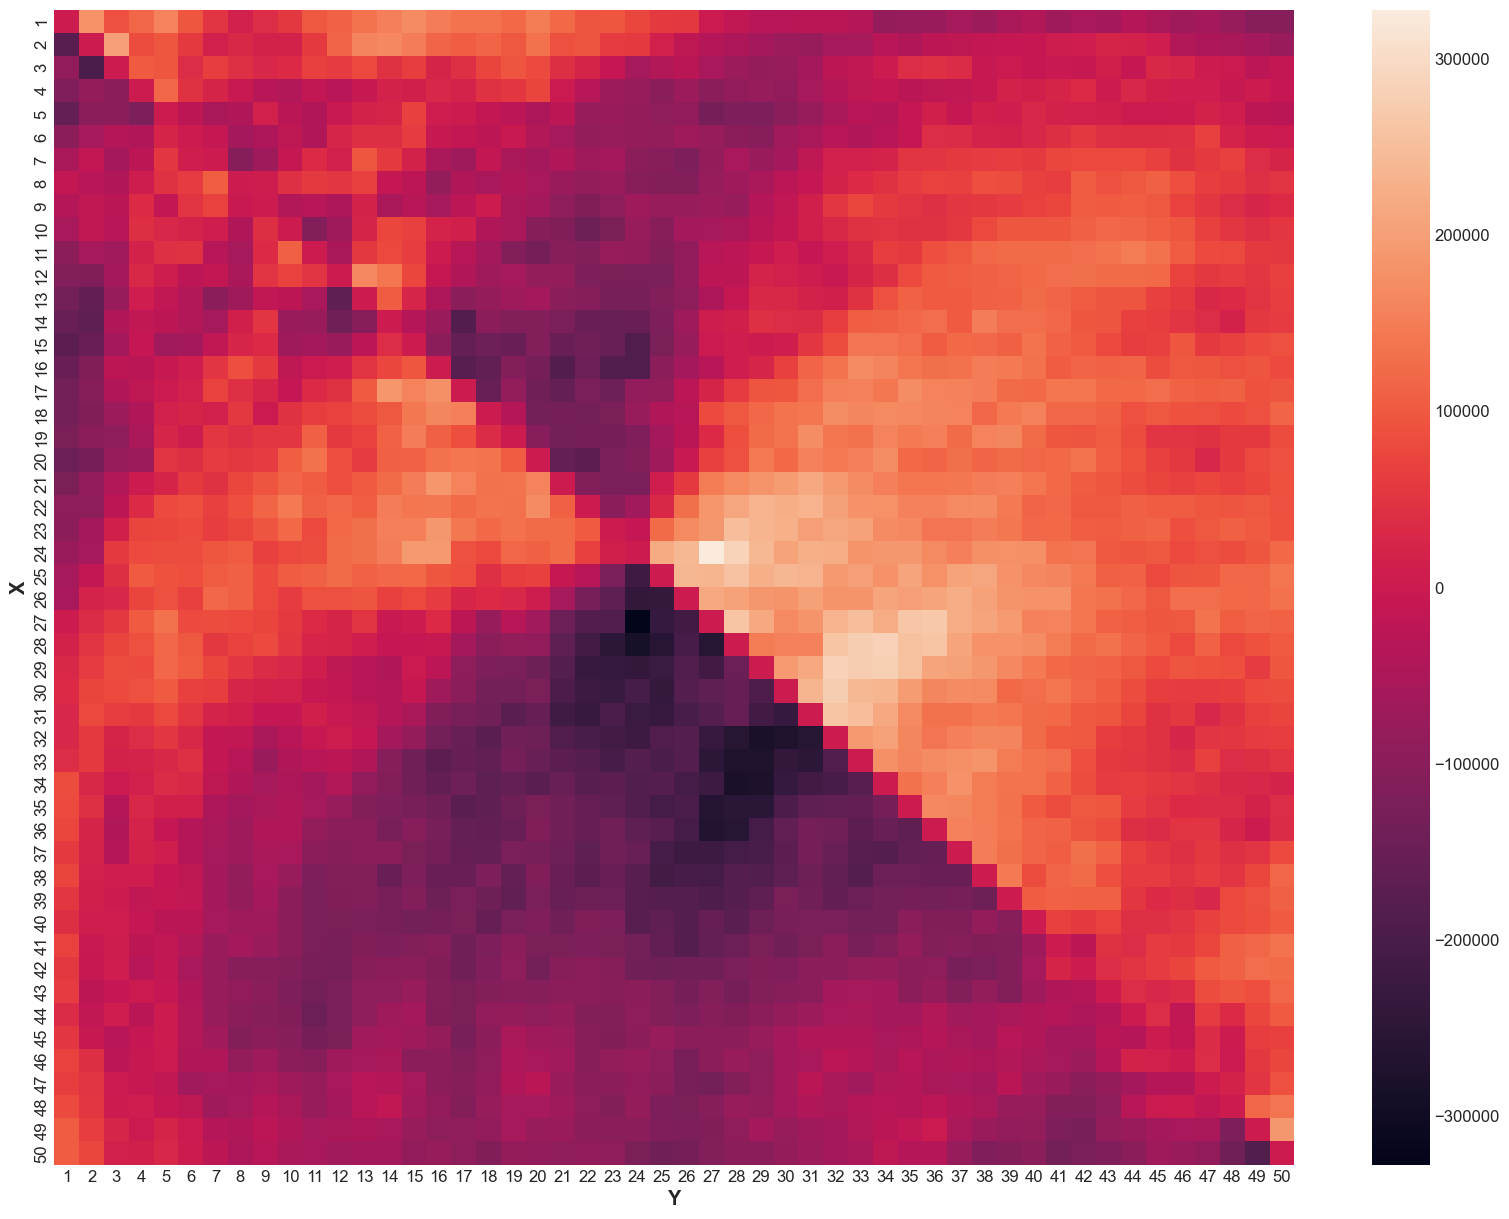

In [80]:
plt.rcParams['figure.figsize'] = 20,15 #sets size of the plot
X = strat_perfs.lma
Y = strat_perfs.sma
Z = strat_perfs.profit
data = pd.DataFrame({'X': X, 'Y': Y, 'Z': Z})
data_pivoted = data.pivot("X", "Y", "Z")
ax = sns.heatmap(data_pivoted)
plt.show()

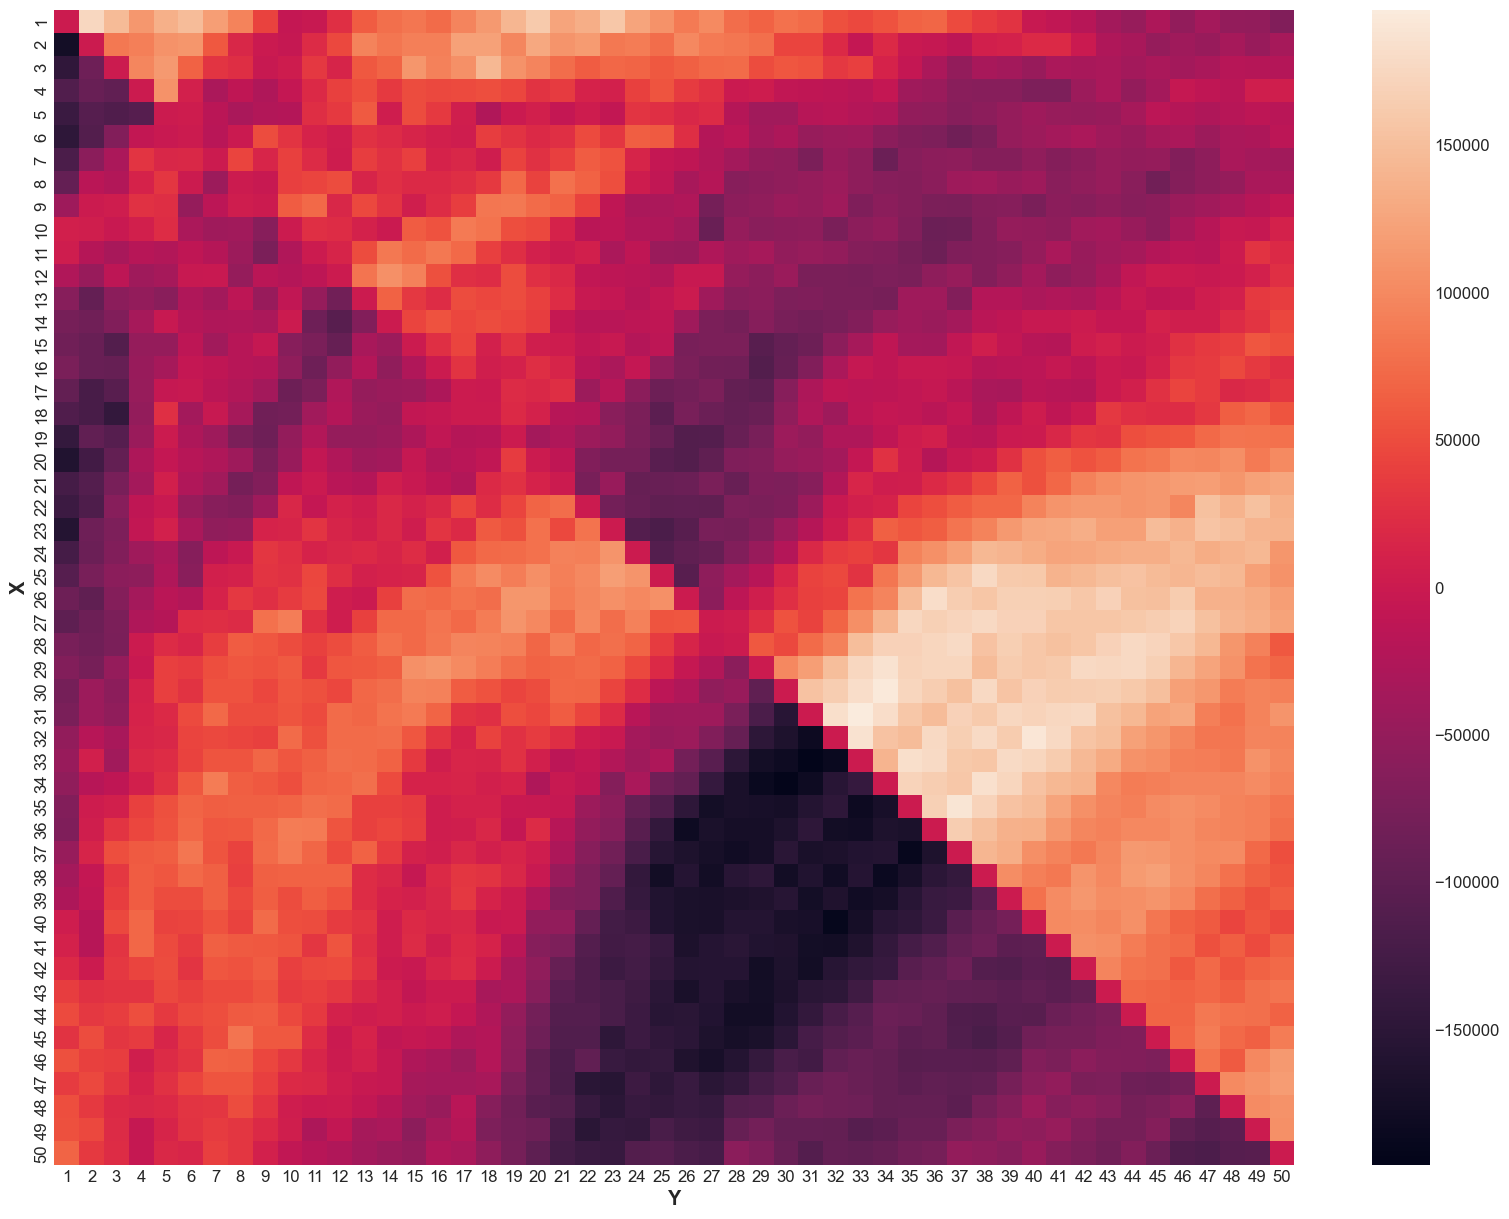

In [81]:
plt.rcParams['figure.figsize'] = 20,15 #sets size of the plot
X = strat_perfs_w.lwma
Y = strat_perfs_w.swma
Z = strat_perfs_w.profit
data = pd.DataFrame({'X': X, 'Y': Y, 'Z': Z})
data_pivoted = data.pivot("X", "Y", "Z")
ax = sns.heatmap(data_pivoted)
plt.show()

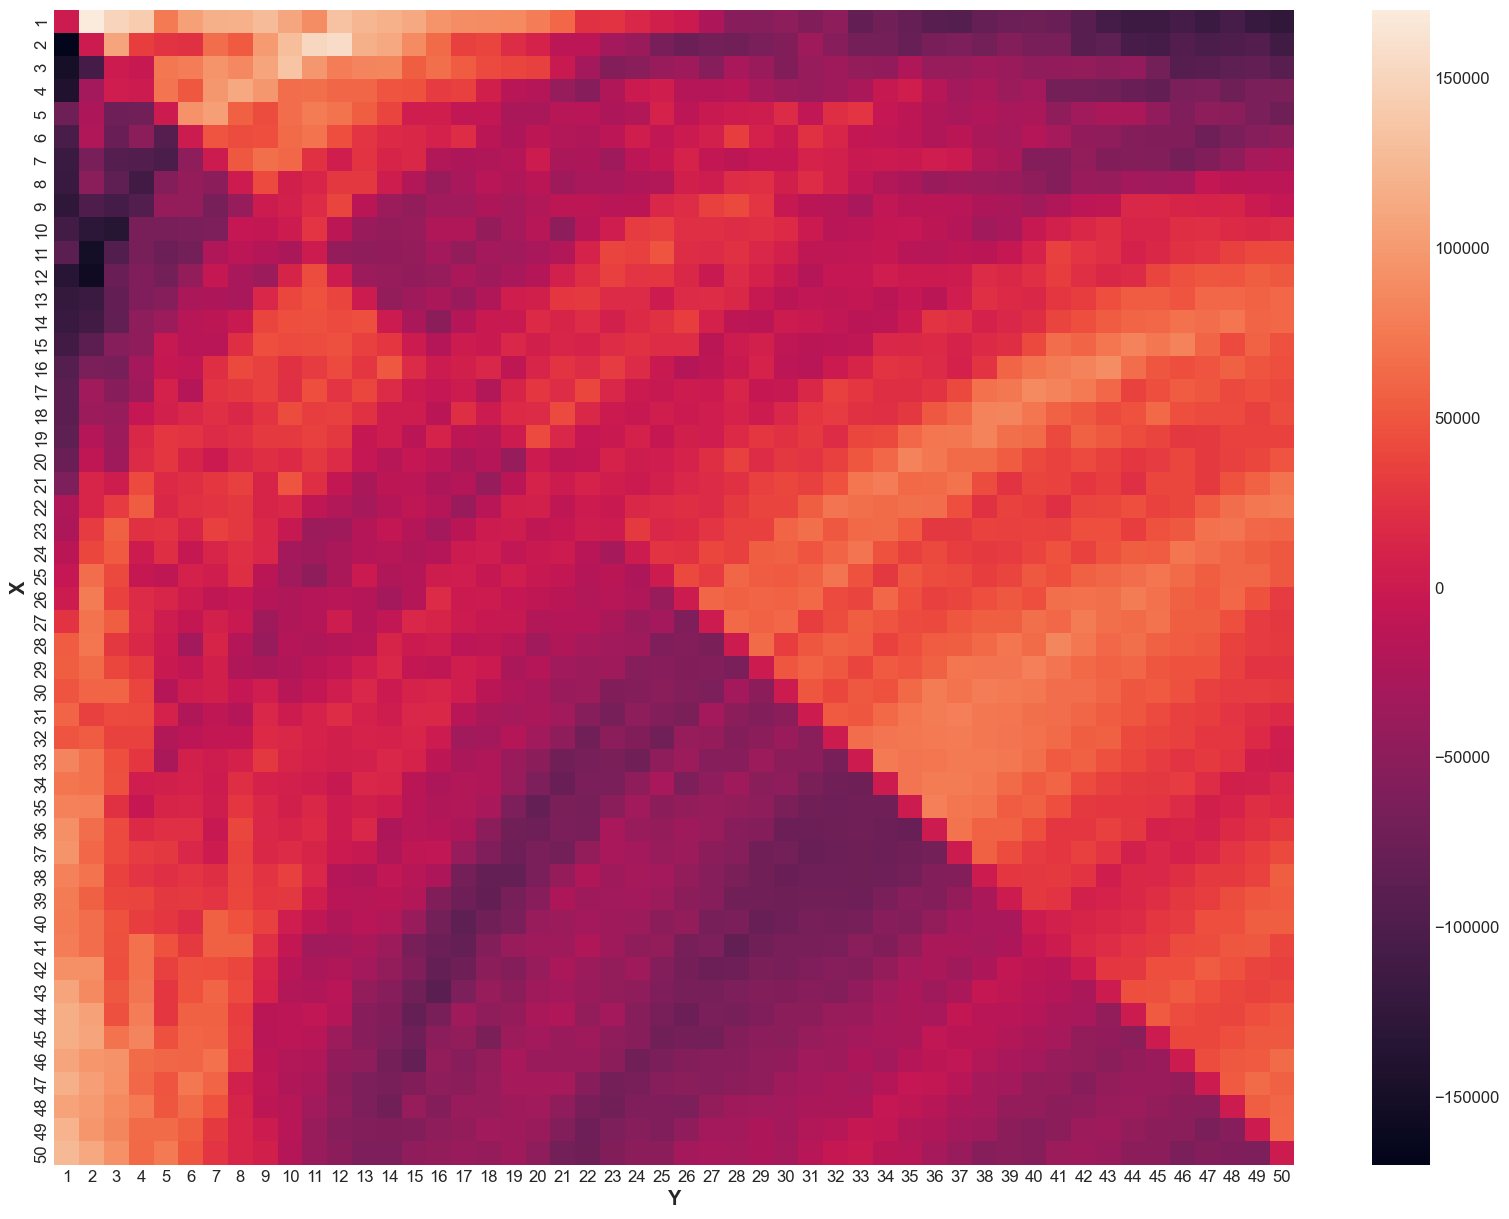

In [82]:
plt.rcParams['figure.figsize'] = 20,15 #sets size of the plot
X = strat_perfs_e.lema
Y = strat_perfs_e.sema
Z = strat_perfs_e.profit
data = pd.DataFrame({'X': X, 'Y': Y, 'Z': Z})
data_pivoted = data.pivot("X", "Y", "Z")
ax = sns.heatmap(data_pivoted)
plt.show()

In [83]:
# THINGS TO WORK ON
# 2.FIND A WAY TO ITERATE THROUGH LIST OF TIME PERIODS
# 3.CALCULATE AND IMPLEMENT WMA'S
# 5.CALCULATE TOTAL TRANSACTION FEES
# 6.INVESTIGATE THAT SYSTEM RESULTS ARE CORRECT
# 7.FIND A WAY TO INCORPORATE TICK/VOLUME CANDLE DATA IN ANY WAY POSSIBLE
# 8.LEARN HOW TO USE A TRADING API
# 9.LEARN TO USE JAVASCRIPT/C# IF NECESSARY
# 11.CONSIDER ADDING THE COLUMNS AND ENRICHING THE DATA IN THE WAYS YOU DREAMT ABOUT
#    -DIFFERENCE BETWEEN SMA & LMA
#     -RELATIVE VOLUME OR DIFFERENCE BETWEEN VOLUME AND VMA
#      -MOVING AVERAGE RIBBON AND SUM OF DIFFERENCE
#       -RSI CALCULATION
#        -LOCAL HIGHS AND LOWS
#         -VWAP CALCULATION
#          -
# 12. CONSIDER CONCATENATING THE MOVING AVERAGE VALUES TO MAKE THE TABLE SMALLER
#    -YOU WILL HAVE TO FIGURE OUT HOW TO ACCESS THESE SUBSTRINGS FOR CALCULATING SIGNALS

### VVV Experimental Code